In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_countries_hpi = pd.read_parquet('../data/clean_hpi.parquet')
df_countries_hpi.head()

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,...,Slovenia,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom
0,2010,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,99.9975,100.0025,100.0000,...,99.9975,100.0000,99.9975,100.0025,100.0025,100.0000,100.0000,100.0000,100.00,100.0000
1,2011,97.8450,104.2250,103.5825,119.0225,94.4900,105.7500,112.2300,104.1175,107.8900,...,102.7150,103.5900,105.2275,92.3550,102.5800,107.5100,104.2625,108.8000,97.24,98.5450
2,2012,97.5325,117.1325,106.0150,133.0600,92.6900,110.6150,124.0250,103.4225,118.7925,...,95.6325,108.4075,108.2500,78.7075,103.8650,113.7225,107.6325,120.6750,101.82,98.9200
3,2013,103.9925,122.5900,107.5900,145.3175,90.6500,112.7600,136.5175,109.5550,130.0650,...,90.6200,115.4075,107.8000,71.5250,109.2225,118.3000,115.9925,134.4625,111.83,101.4550
4,2014,113.4075,126.7900,107.2250,155.3575,91.9475,118.8625,154.7200,112.3775,140.7525,...,84.6400,123.9875,109.4325,71.7450,119.5200,121.4650,127.0725,151.2500,118.88,109.6025


In [3]:
df_clusters = pd.read_parquet('../data/clusters/clusters_kmean_random.parquet')
df_clusters

,Country,iso_a3,cluster,CONTINENT
0,Australia,AUS,1,Oceania
1,Austria,AUT,0,Europe
2,Belgium,BEL,0,Europe
3,Brazil,BRA,1,South America
4,Bulgaria,BGR,0,Europe
5,Canada,CAN,1,North America
6,Chile,CHL,2,South America
7,Colombia,COL,2,South America
8,Croatia,HRV,0,Europe
9,Cyprus,CYP,0,Asia


In [4]:
def find_countries_missing_from_clusters(df_hpi, df_clusters, country_column='Country'):
    """
    Identifies which countries are present in the HPI DataFrame but missing from the cluster DataFrame.
    Handles country name formatting differences (e.g., '-' vs ' ') and ignores the year column.

    Parameters:
    - df_hpi: DataFrame where columns are country names and rows are years (House Price Index data)
    - df_clusters: DataFrame with country names and cluster assignments
    - country_column: Name of the column in df_clusters that contains country names (default: 'Country')

    Returns:
    - List of country names that are in df_hpi but not in df_clusters
    """

    # Step 1: Remove the year column (assumed to be the first column)
    hpi_country_columns = df_hpi.columns[1:]

    # Step 2: Normalize country names by replacing '-' with ' '
    hpi_countries = set(col.replace('-', '-').strip() for col in hpi_country_columns)

    # Step 3: Normalize cluster country names
    cluster_countries = set(df_clusters[country_column].str.strip())

    # Step 4: Find missing countries
    missing_countries = hpi_countries - cluster_countries

    # Step 5: Print results
    if missing_countries:
        print("Countries in HPI that are missing from the cluster DataFrame:")
        for country in sorted(missing_countries):
            print(f" - {country}")
    else:
        print("All countries in the HPI DataFrame are present in the cluster DataFrame.")

    return list(missing_countries)

In [5]:
countries_delete = find_countries_missing_from_clusters(df_countries_hpi, df_clusters)

Countries in HPI that are missing from the cluster DataFrame:
 - China
 - Hong-Kong
 - Indonesia
 - Macedonia
 - Morocco


In [6]:
# Eliminar esas columnas del DataFrame HPI
df_countries_hpi = df_countries_hpi.drop(columns=countries_delete)

In [7]:
df_countries_hpi.shape

(15, 53)

In [8]:
df_clusters.shape

(53, 4)

In [9]:
print(list(df_countries_hpi.columns))

['Year', 'Australia', 'Austria', 'Belgium', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'Colombia', 'Croatia', 'Cyprus', 'Czech-Republic', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Iceland', 'India', 'Ireland', 'Israel', 'Italy', 'Japan', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Mexico', 'Netherlands', 'New-Zealand', 'Norway', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Romania', 'Russia', 'Serbia', 'Singapore', 'Slovakia', 'Slovenia', 'South-Africa', 'South-Korea', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'Turkey', 'USA', 'United-Kingdom']


In [10]:
print(list(df_clusters.Country))

['Australia', 'Austria', 'Belgium', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'Colombia', 'Croatia', 'Cyprus', 'Czech-Republic', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Iceland', 'India', 'Ireland', 'Israel', 'Italy', 'Japan', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Mexico', 'Netherlands', 'New-Zealand', 'Norway', 'Paraguay', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Romania', 'Russia', 'Serbia', 'Singapore', 'Slovakia', 'Slovenia', 'South-Africa', 'South-Korea', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'Turkey', 'United-Kingdom', 'USA']


In [11]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'CONTINENT' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'CONTINENT'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['CONTINENT']
            print(f" - {country} ({continent})")

In [12]:
print_cluster_groups(df_clusters)


🌍 Cluster 0 (17 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Bulgaria (Europe)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Estonia (Europe)
 - Finland (Europe)
 - Greece (Europe)
 - Ireland (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malta (Europe)
 - New-Zealand (Oceania)
 - Portugal (Europe)
 - Slovakia (Europe)
 - Slovenia (Europe)

🌍 Cluster 1 (29 countries):
 - Australia (Oceania)
 - Brazil (South America)
 - Canada (North America)
 - Czech-Republic (Europe)
 - Denmark (Europe)
 - France (Europe)
 - Germany (Europe)
 - Hungary (Europe)
 - Iceland (Europe)
 - Israel (Asia)
 - Italy (Europe)
 - Malaysia (Asia)
 - Mexico (North America)
 - Netherlands (Europe)
 - Norway (Europe)
 - Peru (South America)
 - Philippines (Asia)
 - Poland (Europe)
 - Romania (Europe)
 - Serbia (Europe)
 - Singapore (Asia)
 - South-Africa (Africa)
 - Spain (Europe)
 - Sweden (Europe)
 - Switzerland (Europe)
 - Thailand (Asia)
 - Turkey (Asia)
 - United-Kingdom (Europe

In [13]:
import random

In [14]:
def evaluate_cluster_sampling_errors(df_hpi, df_clusters, cluster_id,
                                     cluster_column='cluster', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None):
    """
    Evaluates synthetic HPI estimation via bootstrap sampling for each country in a cluster.

    Returns:
    - avg_mse: Average MSE across all countries in the cluster
    - avg_mae: Average MAE across all countries in the cluster
    - best_country: Country with the lowest MSE
    - yearly_bootstrap_means: Dict with year as key and synthetic mean using best_country as excluded
    - yearly_mean: Dict with year as key and actual mean HPI of all countries in the cluster
    """
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data.")

    mse_scores = {}
    mae_scores = {}

    for excluded_country in cluster_countries:
        sampling_countries = [c for c in cluster_countries if c != excluded_country]
        synthetic_values = []
        actual_values = []

        for _, row in df_hpi.iterrows():
            year = row[year_column]
            values = row[sampling_countries].dropna().values
            actual_value = row.get(excluded_country, np.nan)

            if len(values) == 0 or np.isnan(actual_value):
                continue

            sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                            for _ in range(n_samples)]
            synthetic_mean = np.mean(sample_means)

            synthetic_values.append(synthetic_mean)
            actual_values.append(actual_value)

        if len(synthetic_values) == 0:
            mse_scores[excluded_country] = np.nan
            mae_scores[excluded_country] = np.nan
        else:
            errors = np.array(synthetic_values) - np.array(actual_values)
            mse_scores[excluded_country] = np.mean(errors ** 2)
            mae_scores[excluded_country] = np.mean(np.abs(errors))

    best_country = min(mse_scores, key=lambda k: mse_scores[k] if not np.isnan(mse_scores[k]) else np.inf)

    # Plot for best country
    if plot:
        synthetic_values = []
        actual_values = []
        years = []

        sampling_countries = [c for c in cluster_countries if c != best_country]

        for _, row in df_hpi.iterrows():
            year = row[year_column]
            values = row[sampling_countries].dropna().values
            actual_value = row.get(best_country, np.nan)

            if len(values) == 0 or np.isnan(actual_value):
                continue

            sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                            for _ in range(n_samples)]
            cumulative_means = [np.mean(sample_means[:j+1]) for j in range(n_samples)]

            lower_bound = np.percentile(sample_means, 2.5)
            upper_bound = np.percentile(sample_means, 97.5)

            fig, axes = plt.subplots(1, 2, figsize=(14, 4))

            axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
            axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {best_country}")
            axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
            axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
            axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
            axes[0].set_xlabel("Sample Mean HPI")
            axes[0].set_ylabel("Frequency")
            axes[0].legend()
            axes[0].grid(True)

            axes[1].plot(cumulative_means, color='purple')
            axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
            axes[1].set_title("Mean Convergence Over Iterations")
            axes[1].set_xlabel("Iteration")
            axes[1].set_ylabel("Cumulative Mean")
            axes[1].legend()
            axes[1].grid(True)

            plt.tight_layout()
            plt.show()

    # Synthetic mean per year using best_country as excluded
    yearly_bootstrap_means = {}
    sampling_countries = [c for c in cluster_countries if c != best_country]

    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row[sampling_countries].dropna().values

        if len(values) == 0:
            continue

        sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                        for _ in range(n_samples)]
        synthetic_mean = np.mean(sample_means)
        yearly_bootstrap_means[year] = synthetic_mean

    # Real mean per year using all countries in the cluster
    yearly_mean = {}
    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row[cluster_countries].dropna().values

        if len(values) == 0:
            continue

        yearly_mean[year] = np.mean(values)

    avg_mse = np.nanmean(list(mse_scores.values()))
    avg_mae = np.nanmean(list(mae_scores.values()))

    return avg_mse, avg_mae, best_country, yearly_bootstrap_means, yearly_mean

In [15]:
def calculate_hpi_variance_by_cluster(df_hpi, df_clusters,
                                      cluster_column='cluster', country_column='Country',
                                      year_column='Year'):
    """
    Calculates average HPI variance across countries for each cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values

    Returns:
    - cluster_variances: dict with cluster_id as key and average variance as value
    """
    cluster_variances = {}

    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        # Get countries in this cluster that are present in HPI data
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            cluster_variances[cluster_id] = np.nan
            continue

        # Extract HPI values for cluster countries
        hpi_values = df_hpi[cluster_countries]

        # Calculate variance across countries for each year
        yearly_variances = hpi_values.var(axis=1, skipna=True)

        # Compute average variance across all years
        avg_variance = yearly_variances.mean()
        cluster_variances[cluster_id] = avg_variance

    return cluster_variances

In [16]:
def plot_cluster_hpi_with_bootstrap(df_hpi, df_clusters, cluster_id,
                                    yearly_bootstrap_means,
                                    yearly_mean,
                                    cluster_column='cluster', country_column='Country',
                                    year_column='Year'):
    """
    Plots HPI values for each country in a cluster over time,
    along with the synthetic bootstrap mean per year and the actual cluster mean.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to plot
    - yearly_bootstrap_means: Dict with year as key and synthetic mean value
    - yearly_mean: Dict with year as key and actual mean HPI of all countries in the cluster
    """
    # Obtener países del cluster
    cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) == 0:
        raise ValueError("No hay países válidos en el cluster para graficar.")

    # Graficar HPI real por país
    plt.figure(figsize=(12, 6))
    for country in cluster_countries:
        country_data = df_hpi[[year_column, country]].dropna()
        plt.plot(country_data[year_column], country_data[country], label=country, alpha=0.6)

    # Graficar curva sintética del bootstrap
    bootstrap_years = sorted(yearly_bootstrap_means.keys())
    bootstrap_values = [yearly_bootstrap_means[year] for year in bootstrap_years]
    plt.plot(bootstrap_years, bootstrap_values, label='Bootstrap Mean', color='black', linewidth=2.5)

    # Graficar media real del cluster (línea discontinua)
    mean_years = sorted(yearly_mean.keys())
    mean_values = [yearly_mean[year] for year in mean_years]
    plt.plot(mean_years, mean_values, label='Real Cluster Mean', color='gray', linestyle='--', linewidth=2.5)

    # Estética del gráfico
    plt.title(f"HPI por País en Cluster {cluster_id} + Medias Sintéticas y Reales")
    plt.xlabel("Año")
    plt.ylabel("Índice HPI")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [17]:
def count_points_within_iqr_by_cluster(df_hpi, df_clusters,
                                       cluster_column='cluster', country_column='Country',
                                       year_column='Year'):
    """
    Cuenta cuántos puntos de HPI están dentro del IQR (Q1–Q3) por cluster.

    Returns:
    - dict con cluster_id como clave y cantidad total de puntos dentro del IQR como valor
    """
    cluster_iqr_counts = {}

    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        # Obtener países del cluster presentes en df_hpi
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            cluster_iqr_counts[cluster_id] = 0
            continue

        # Extraer valores de HPI para esos países
        hpi_values = df_hpi[cluster_countries]

        total_within_iqr = 0

        # Iterar por año
        for _, row in hpi_values.iterrows():
            values = row.dropna().values
            if len(values) < 2:
                continue

            q1 = np.percentile(values, 25)
            q3 = np.percentile(values, 75)

            # Contar cuántos valores están dentro del IQR
            count = np.sum((values >= q1) & (values <= q3))
            total_within_iqr += count

        cluster_iqr_counts[cluster_id] = total_within_iqr

    return cluster_iqr_counts

In [18]:
def plot_hpi_boxplots_by_year(df_hpi, year_column='Year', figsize=(14, 6)):
    """
    Plots box plots of HPI values for each year to visualize outliers.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - figsize: Size of the plot (default: (14, 6))
    """

    # Step 1: Melt the DataFrame to long format
    df_long = df_hpi.melt(id_vars=year_column, var_name='Country', value_name='HPI')

    # Step 2: Create boxplot grouped by year
    plt.figure(figsize=figsize)
    df_long.boxplot(column='HPI', by=year_column, grid=False, showfliers=True)

    # Step 3: Customize plot
    plt.title("Box Plot of HPI Values by Year")
    plt.suptitle("")  # Remove default title
    plt.xlabel("Year")
    plt.ylabel("House Price Index (HPI)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [34]:
def plot_hpi_dispersion_by_cluster(df_hpi, df_clusters,
                                    cluster_column='cluster', country_column='Country',
                                    year_column='Year'):
    """
    Plots the dispersion of HPI values for each cluster using boxplots.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    """
    # Crear lista para almacenar datos
    records = []

    # Iterar sobre cada cluster
    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            continue

        # Extraer valores de HPI por país y año
        for _, row in df_hpi.iterrows():
            year = row[year_column]
            for country in cluster_countries:
                value = row.get(country, np.nan)
                if not np.isnan(value):
                    records.append({
                        'Cluster': f'Cluster {cluster_id}',
                        'Country': country,
                        'Year': year,
                        'HPI': value
                    })

    # Convertir a DataFrame
    df_plot = pd.DataFrame(records)

    # Crear boxplot
    plt.figure(figsize=(12, 6))
    sns.boxplot(hue='Cluster', y='HPI', data=df_plot, palette='Set2', x='Cluster')
    plt.title('HPI Dispersion by Cluster')
    plt.ylabel('Human Potential Index (HPI)')
    plt.xlabel('Cluster')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

<Figure size 1400x600 with 0 Axes>

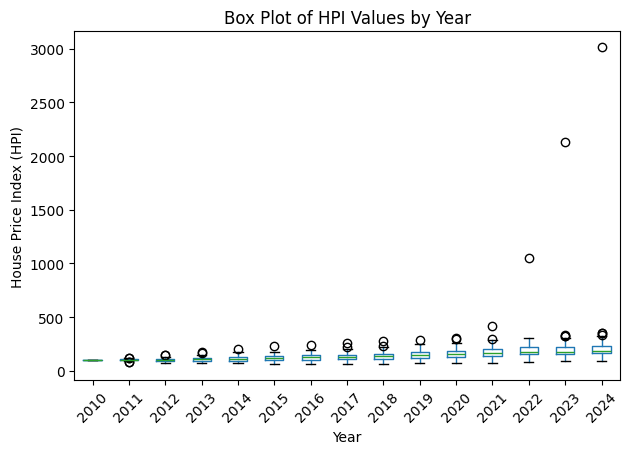

In [19]:
plot_hpi_boxplots_by_year(df_countries_hpi)

In [20]:
def detect_hpi_outliers_by_year(df_hpi, year_column='Year'):
    """
    Detects outliers in HPI values for each year and country using IQR method.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')

    Returns:
    - Dictionary with structure:
      {
        year1: {country1: value, country2: value, ...},
        year2: {...},
        ...
      }
    """

    outliers_by_year = {}

    # Iterate over each year
    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row.drop(labels=year_column).dropna()

        # Compute IQR
        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Detect outliers
        outliers = values[(values < lower_bound) | (values > upper_bound)]

        if not outliers.empty:
            outliers_by_year[year] = outliers.to_dict()

    return outliers_by_year

In [21]:
outliers = detect_hpi_outliers_by_year(df_countries_hpi)
outliers

{np.float64(2011.0): {'India': 122.2475,
  'Ireland': 82.9275,
  'Peru': 120.4325,
  'Russia': 79.19},
 np.float64(2012.0): {'India': 151.8775, 'Peru': 143.1275},
 np.float64(2013.0): {'India': 173.92, 'Peru': 162.8475},
 np.float64(2014.0): {'India': 199.65},
 np.float64(2015.0): {'India': 226.7925},
 np.float64(2016.0): {'India': 241.95499999999998},
 np.float64(2017.0): {'India': 262.3075, 'Turkey': 218.8125},
 np.float64(2018.0): {'India': 277.255, 'Turkey': 235.9525},
 np.float64(2019.0): {'India': 286.46},
 np.float64(2020.0): {'India': 293.6175, 'Turkey': 306.1225},
 np.float64(2021.0): {'India': 301.0675, 'Turkey': 421.0475},
 np.float64(2022.0): {'Turkey': 1052.51},
 np.float64(2023.0): {'Chile': 331.2325,
  'Iceland': 322.8275,
  'India': 323.71500000000003,
  'Turkey': 2129.5299999999997},
 np.float64(2024.0): {'Chile': 354.52,
  'Iceland': 350.135,
  'India': 335.6975,
  'Turkey': 3014.125}}

In [22]:
from scipy.stats.mstats import winsorize

In [23]:
def round_and_winsorize_hpi(df_hpi, year_column='Year', limits=(0.05, 0.05)):
    """
    Rounds all HPI values to two decimals, then applies Winsorization per year.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - limits: Tuple indicating proportion to cut from each tail (default: 10%)

    Returns:
    - DataFrame with rounded and Winsorized HPI values
    """

    # Step 1: Round all numeric values to 2 decimals
    df_rounded = df_hpi.copy()
    country_columns = [col for col in df_rounded.columns if col != year_column]
    df_rounded[country_columns] = df_rounded[country_columns].round(2)

    # Step 2: Apply Winsorization row by row
    df_winsorized = df_rounded.copy()

    for idx, row in df_rounded.iterrows():
        values = row[country_columns].values.astype(float)

        # Apply Winsorization only if enough valid values
        if np.count_nonzero(~np.isnan(values)) >= 4:
            winsorized = winsorize(values, limits=limits)
            df_winsorized.loc[idx, country_columns] = winsorized

    return df_winsorized

In [24]:
df_hpi_winsorized = round_and_winsorize_hpi(df_countries_hpi, limits=(0.078, 0.078))

In [25]:
outliers_after_win = detect_hpi_outliers_by_year(df_hpi_winsorized)
outliers_after_win

{}

<Figure size 1400x600 with 0 Axes>

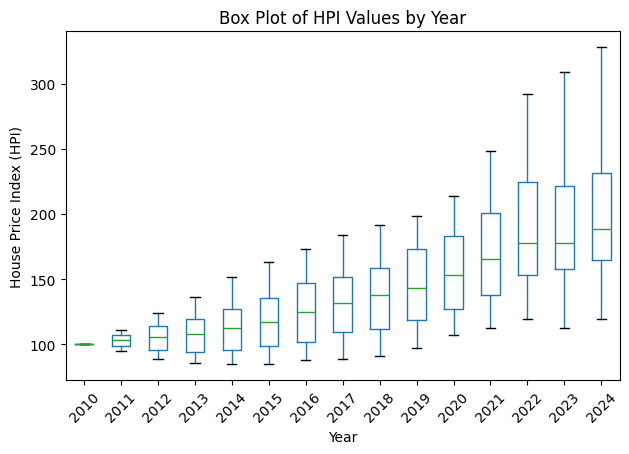

In [26]:
plot_hpi_boxplots_by_year(df_hpi_winsorized)

### Experiment

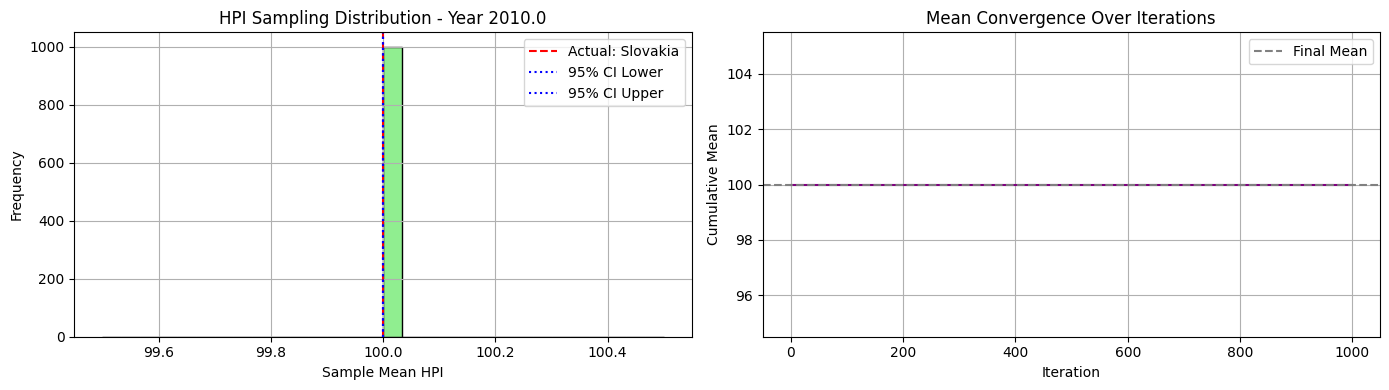

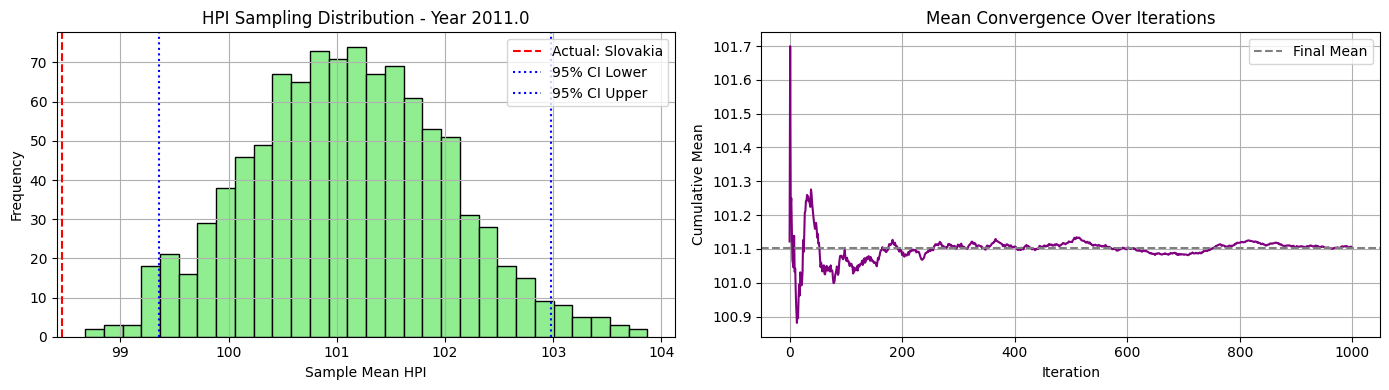

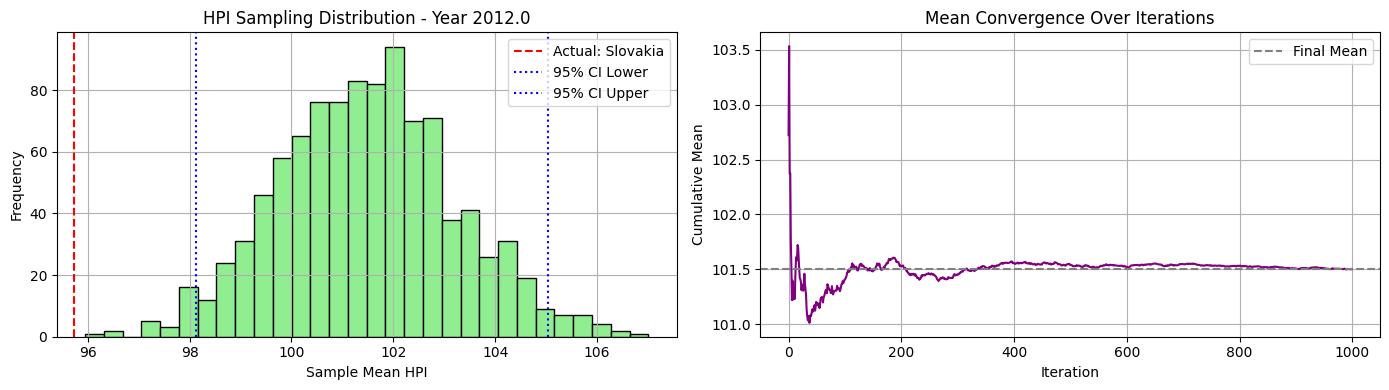

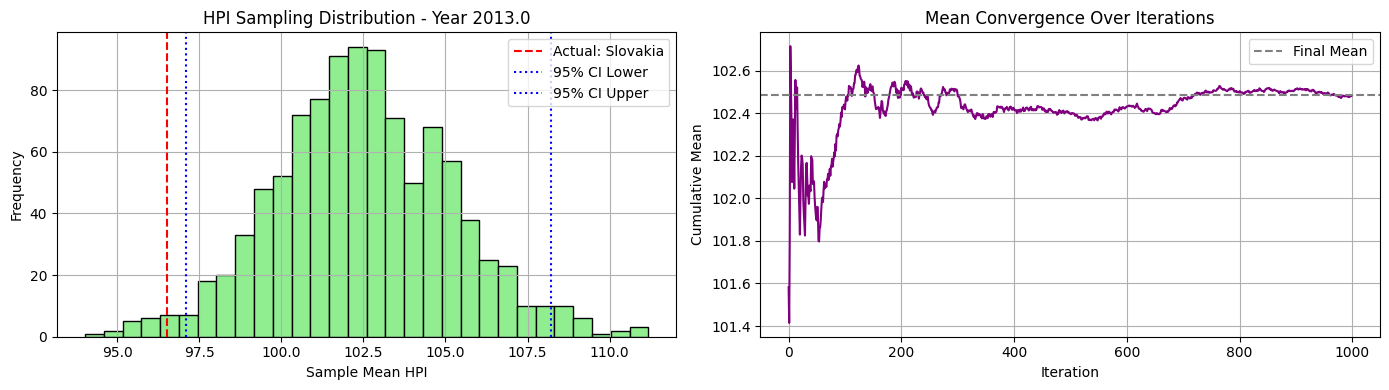

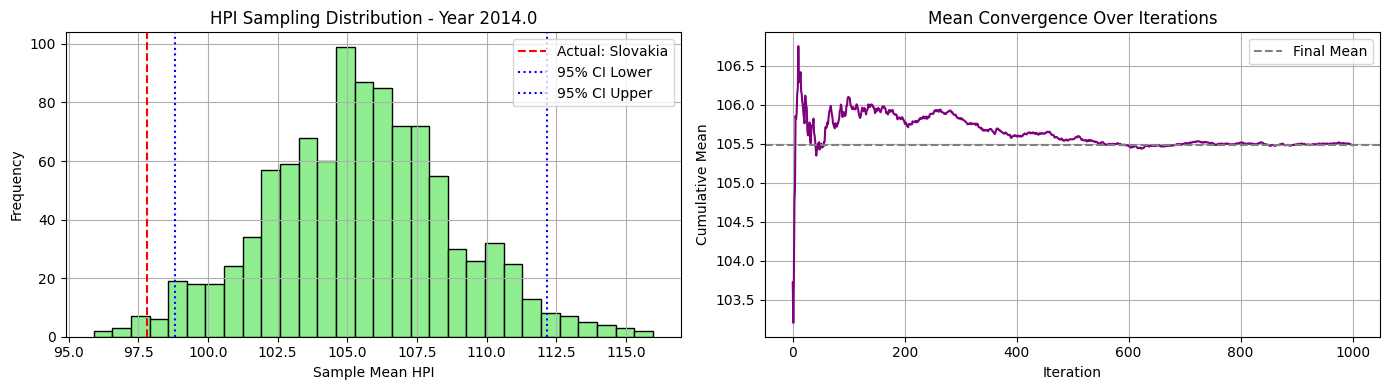

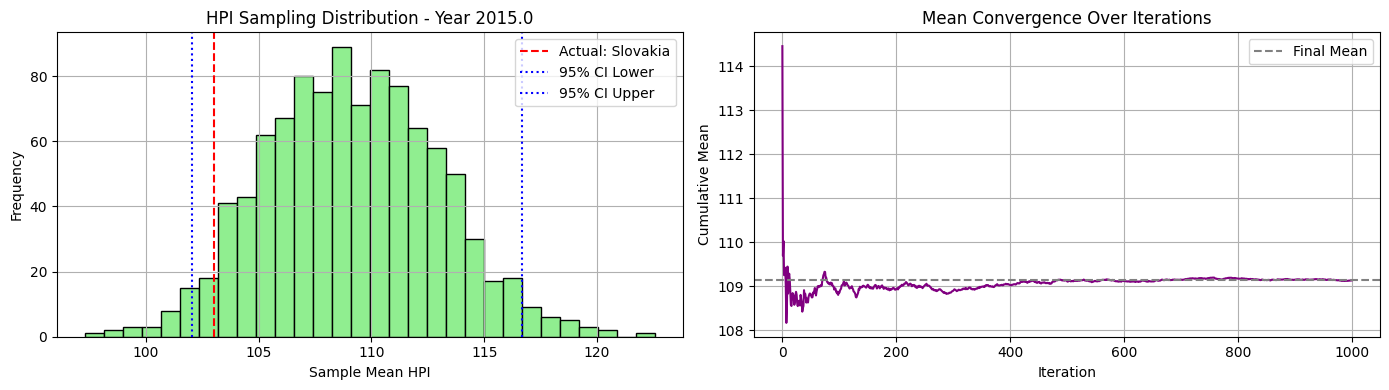

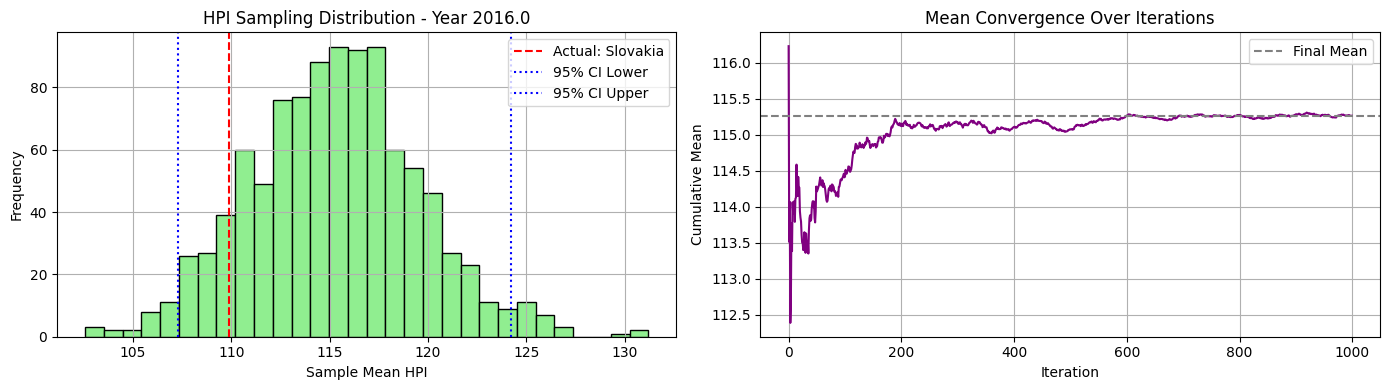

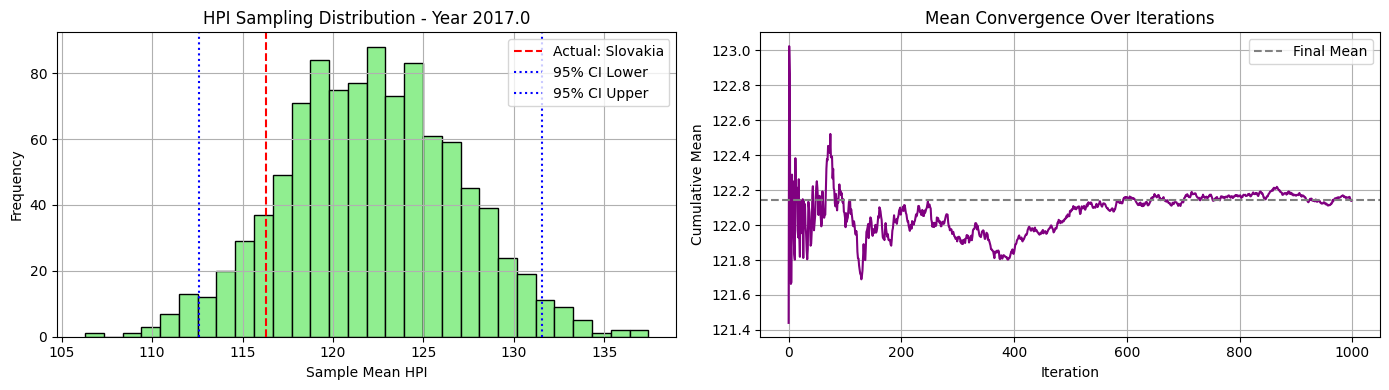

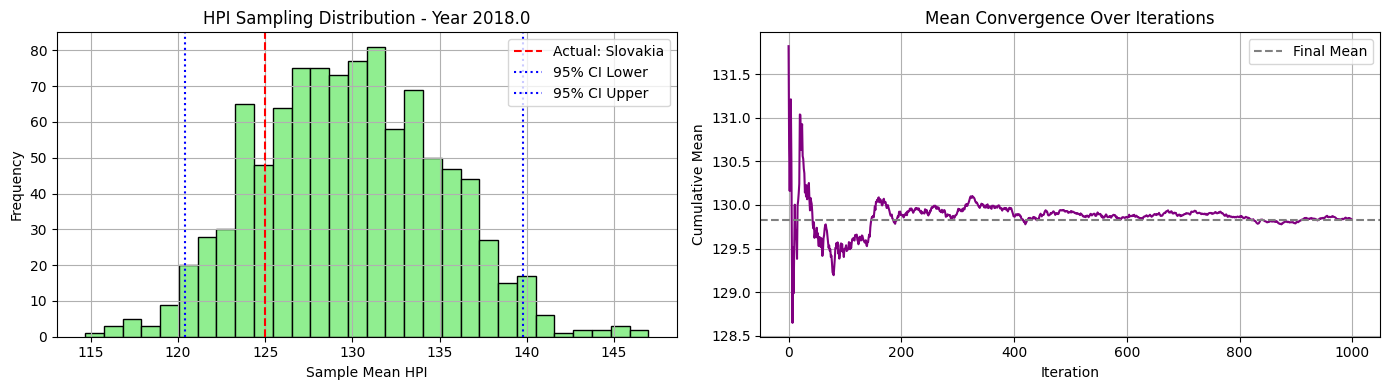

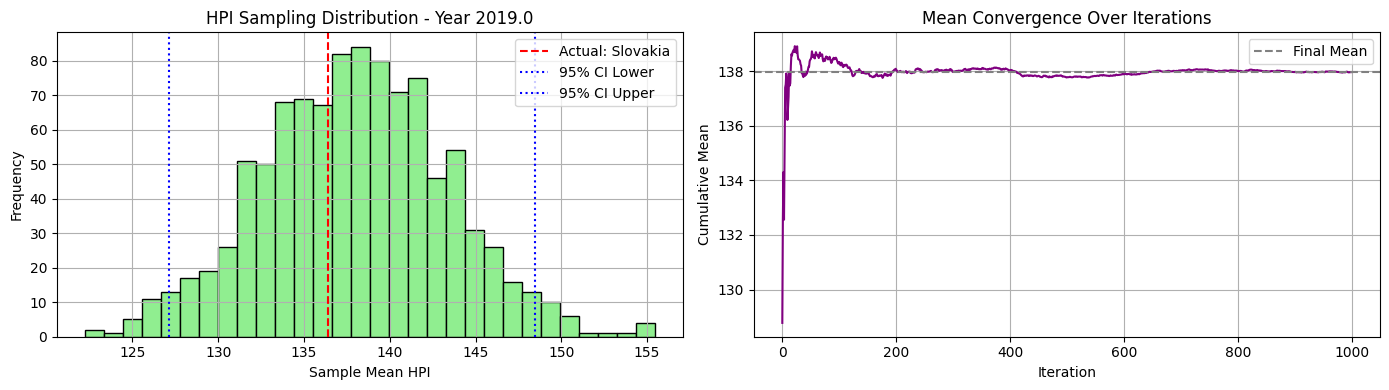

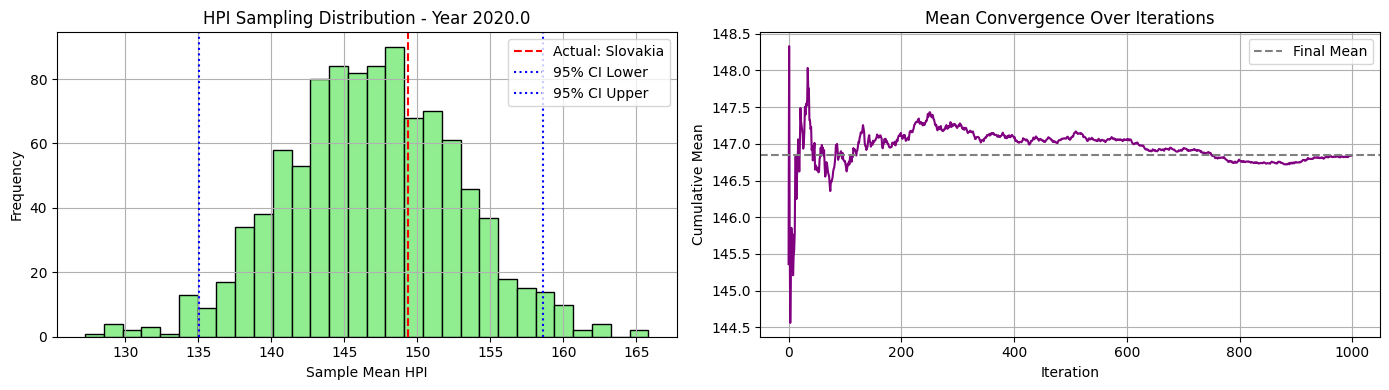

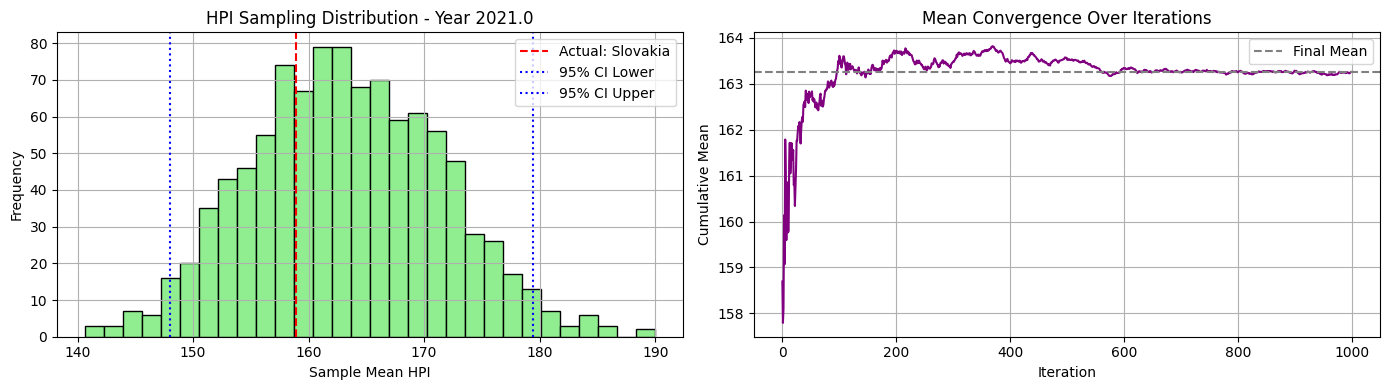

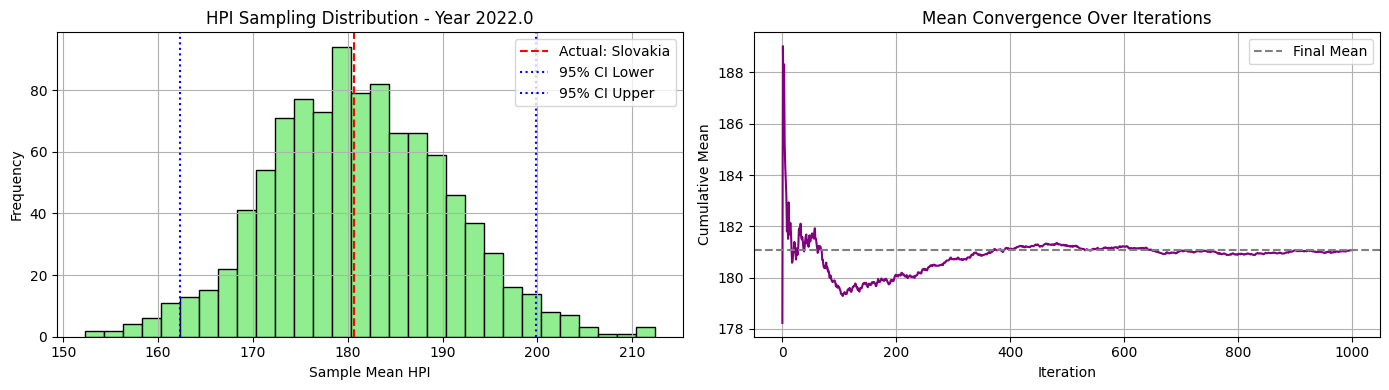

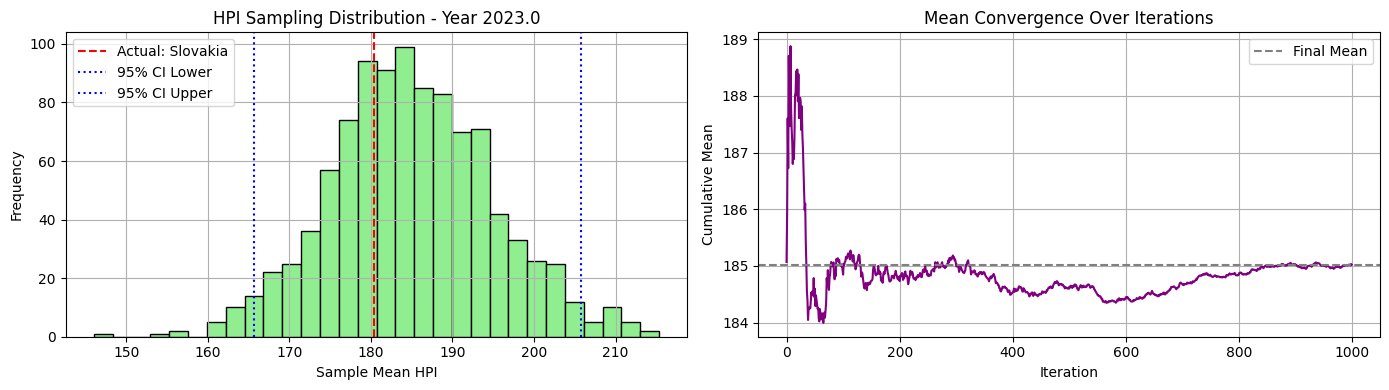

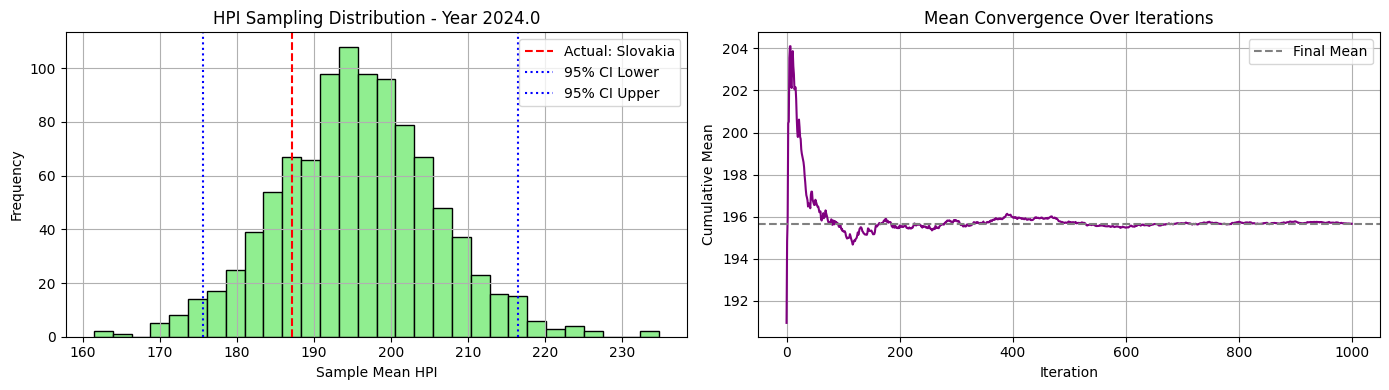

In [27]:
avg_mse_00, avg_mae_00, best_country_00, yearly_bootstrap_means_00, yearly_mean_00 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters, cluster_id=0)

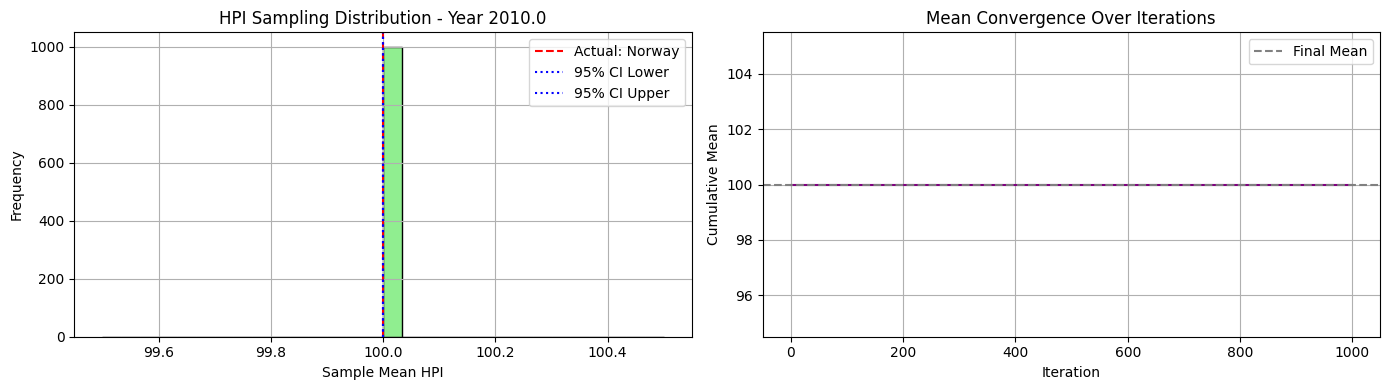

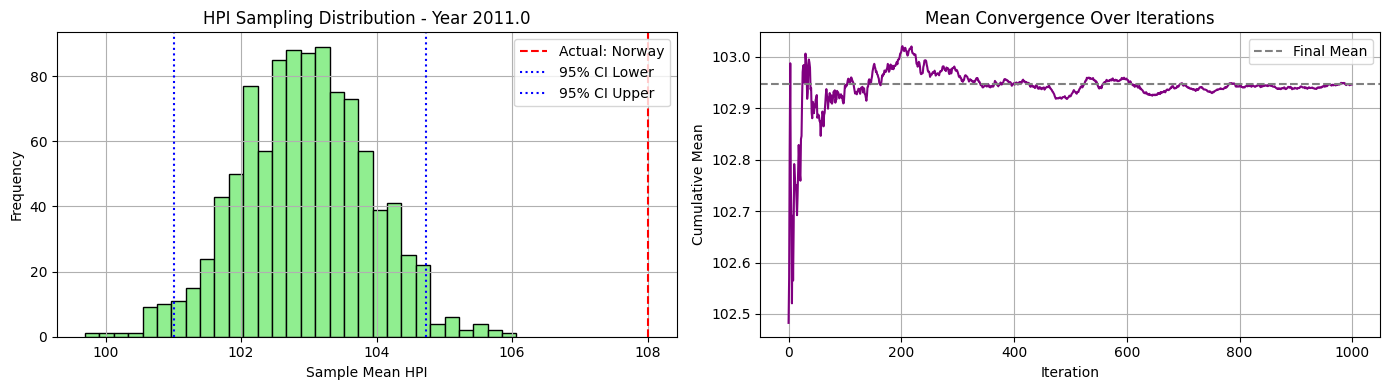

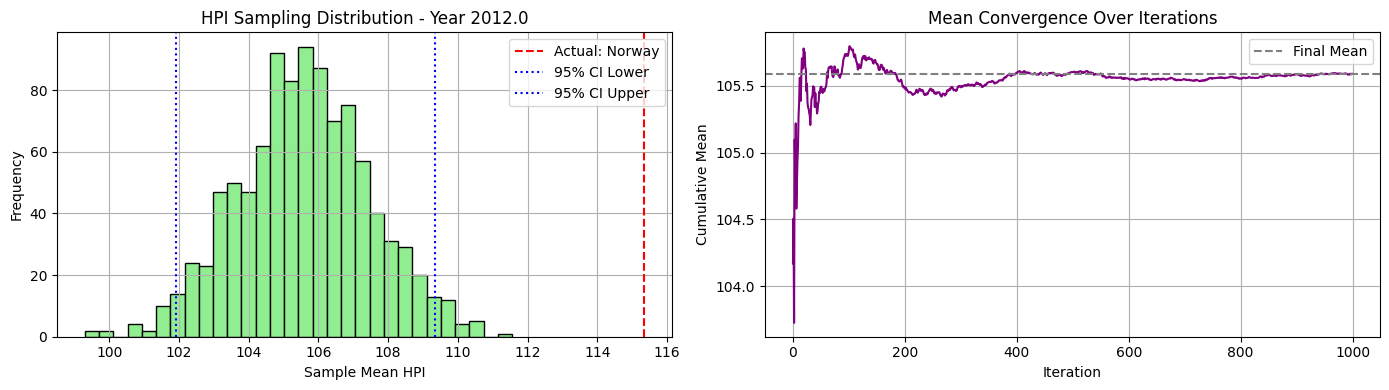

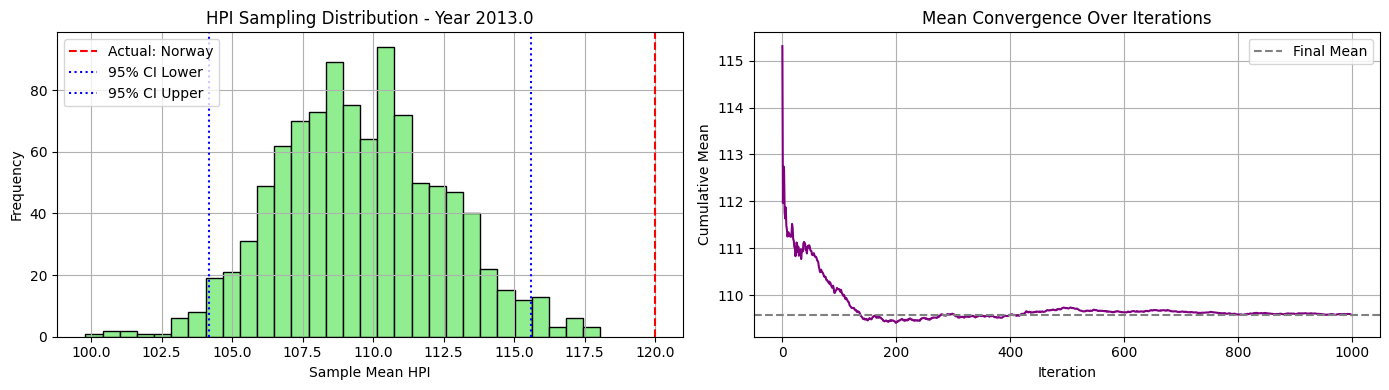

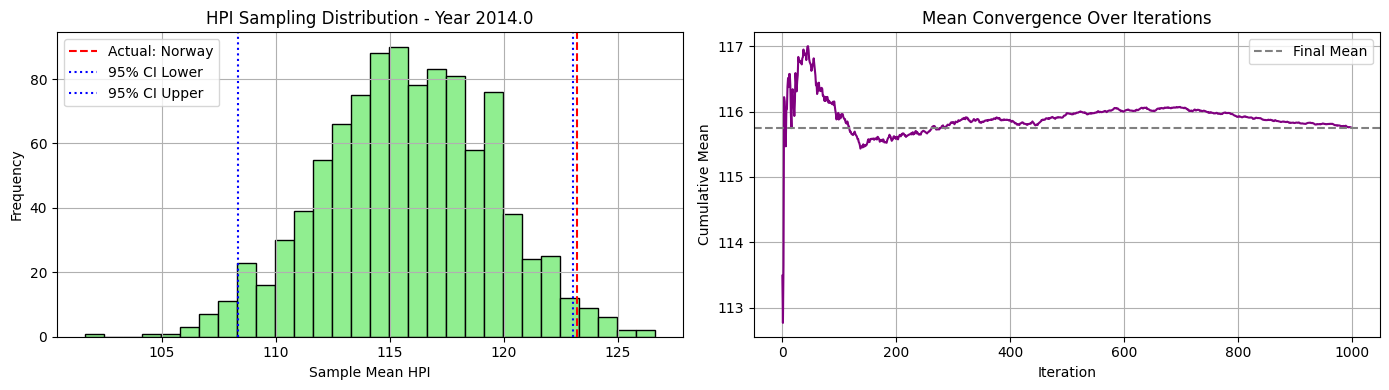

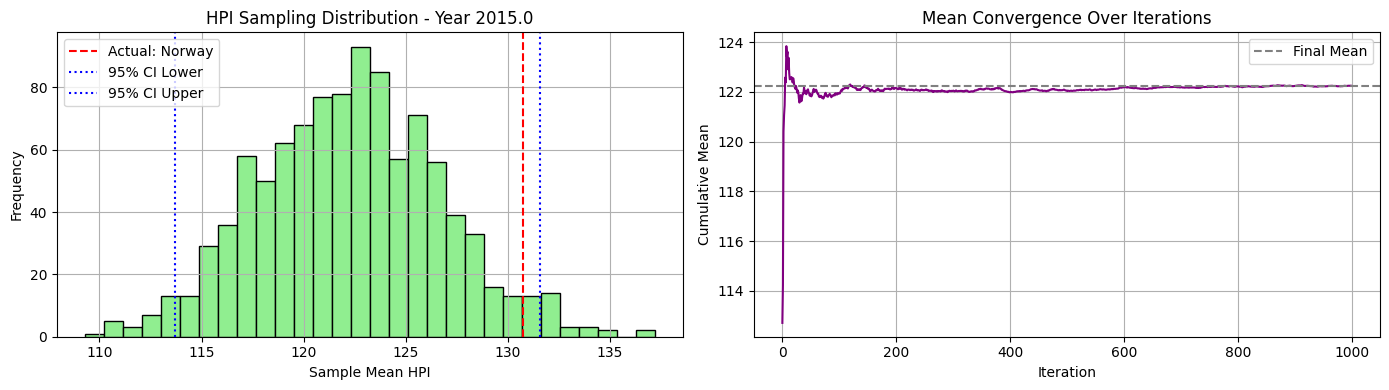

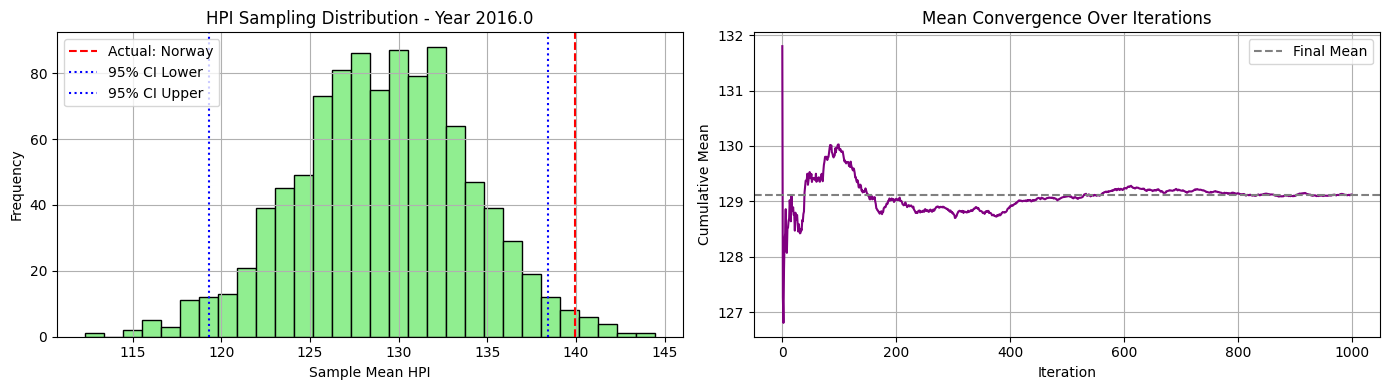

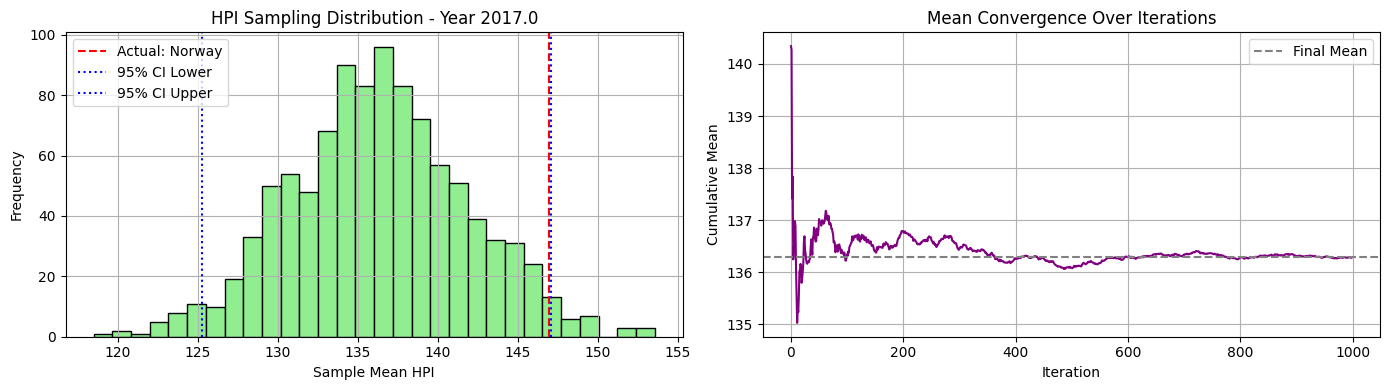

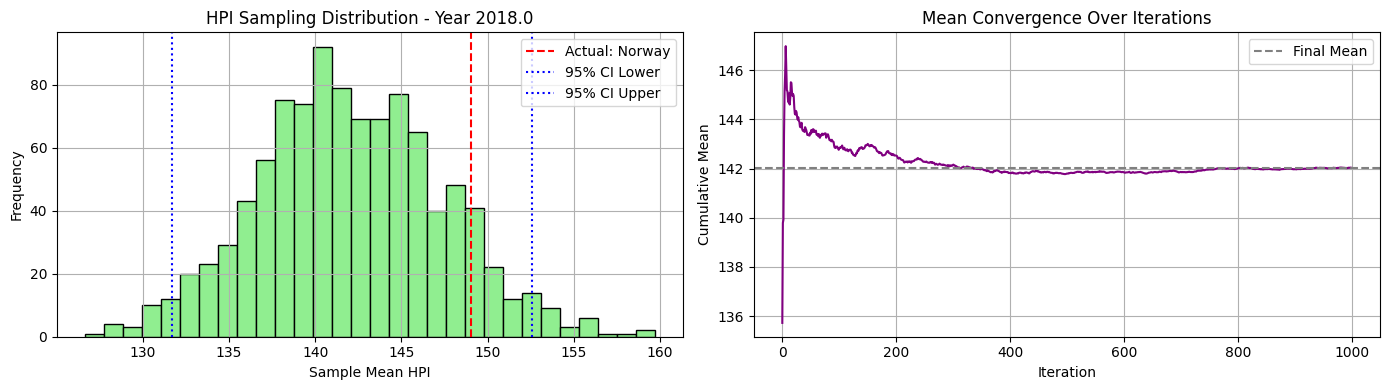

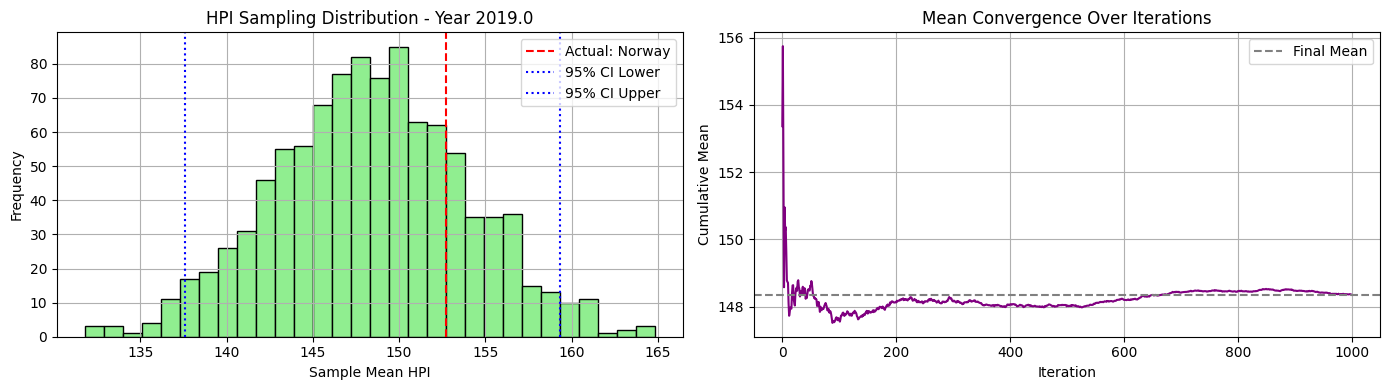

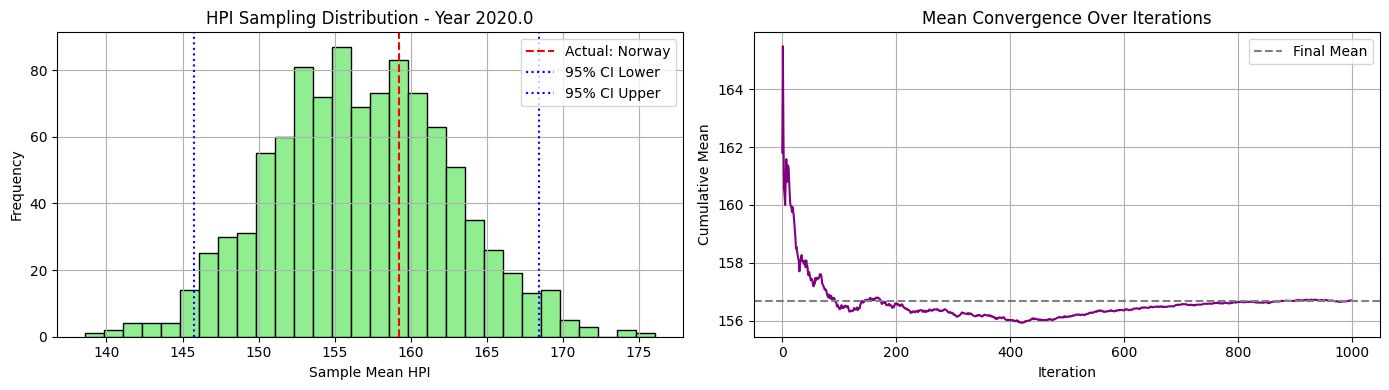

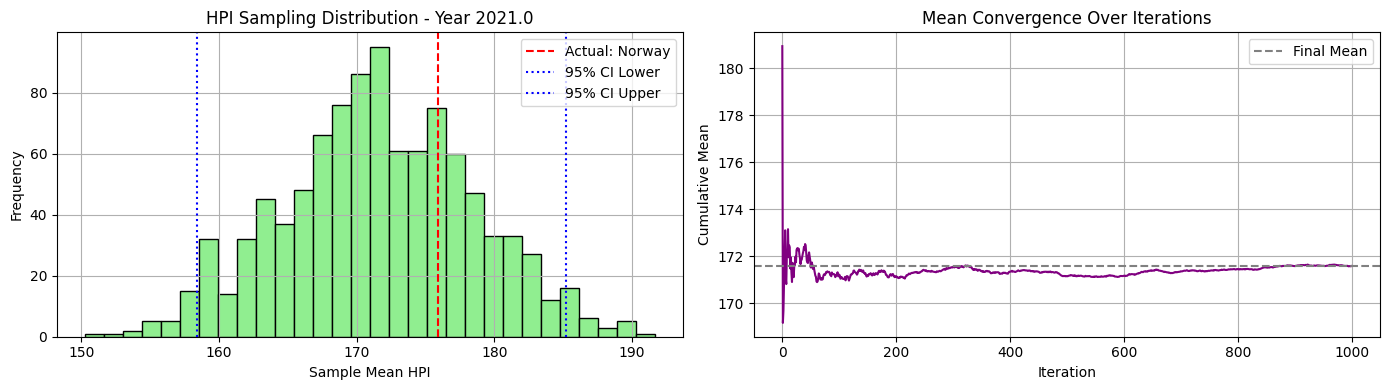

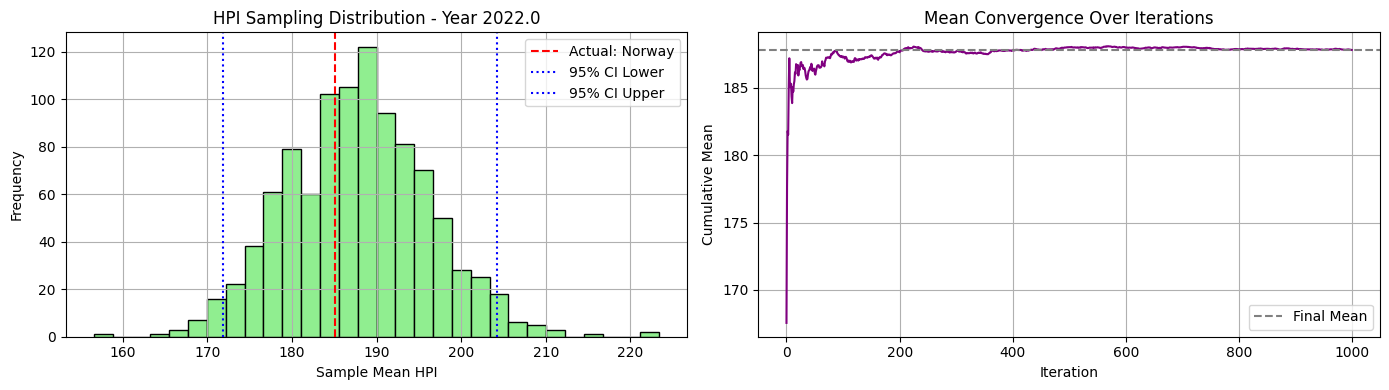

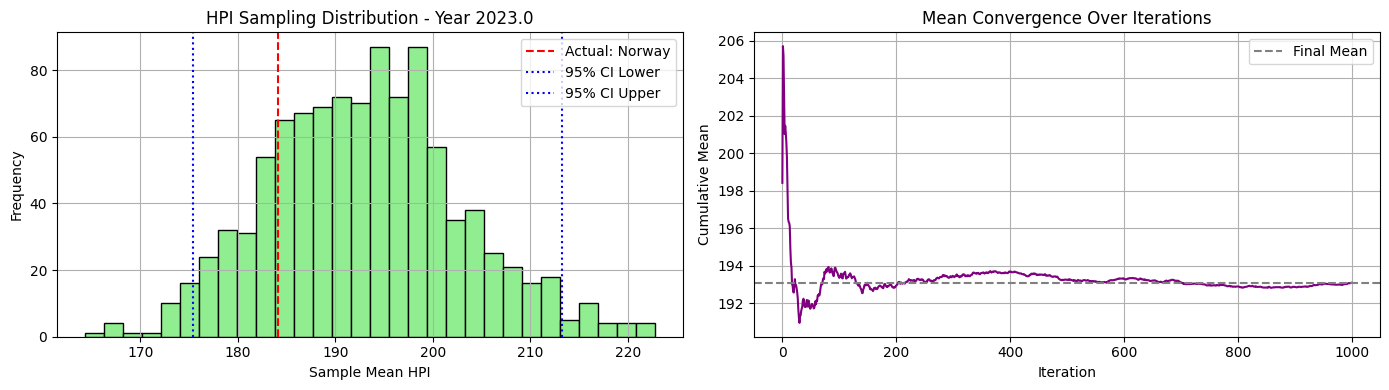

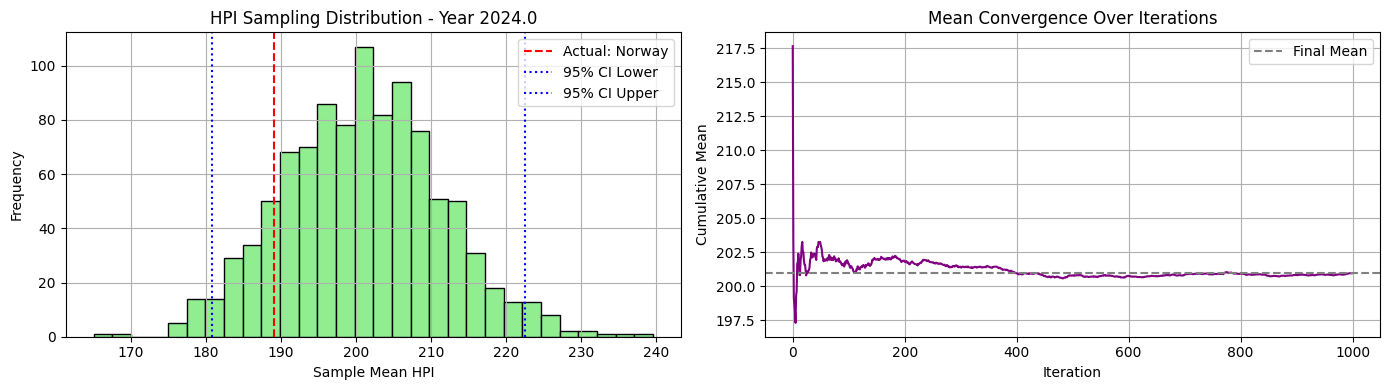

In [28]:
avg_mse_01, avg_mae_01, best_country_01, yearly_bootstrap_means_01, yearly_mean_01 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters, cluster_id=1)

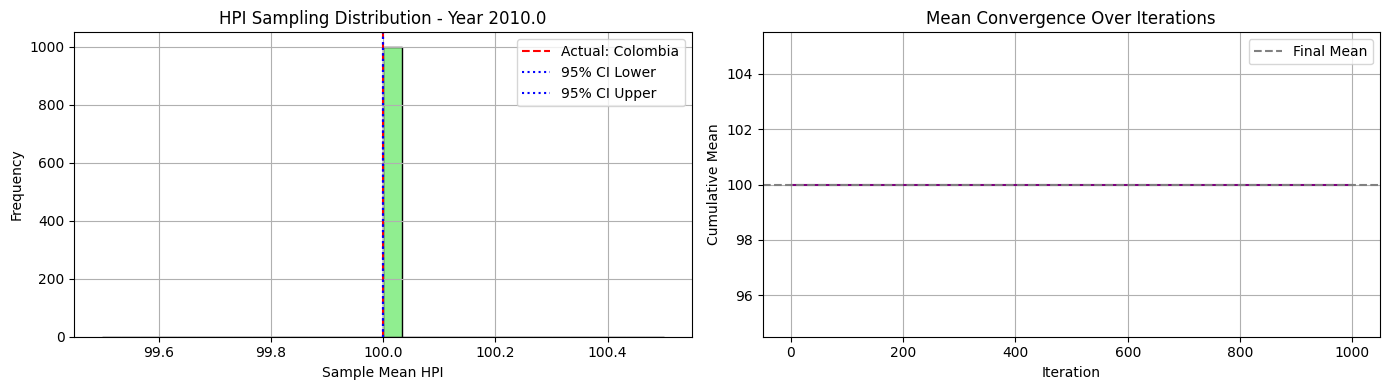

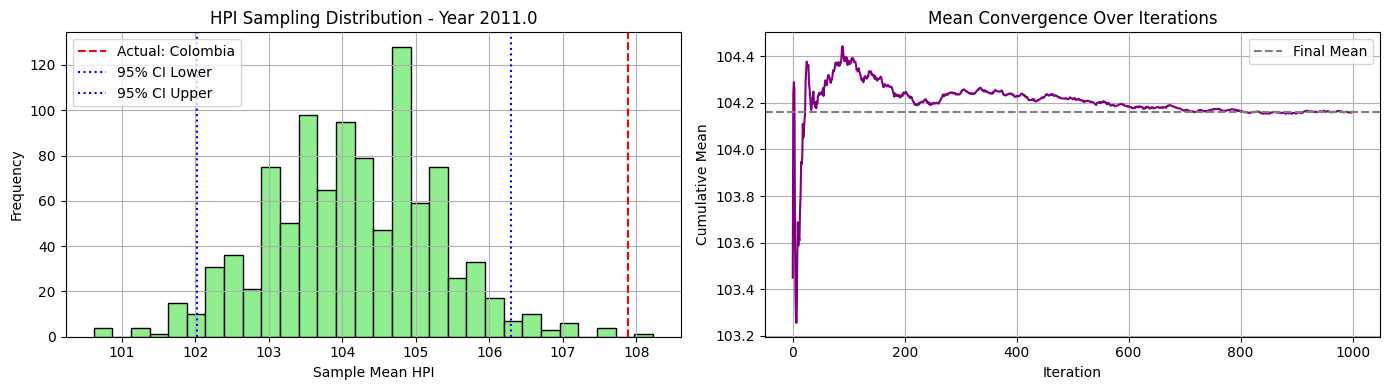

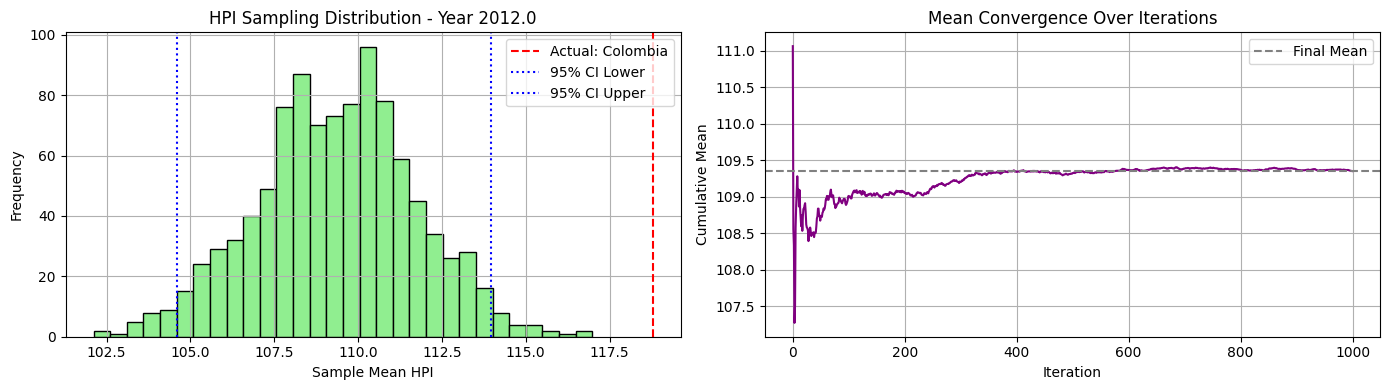

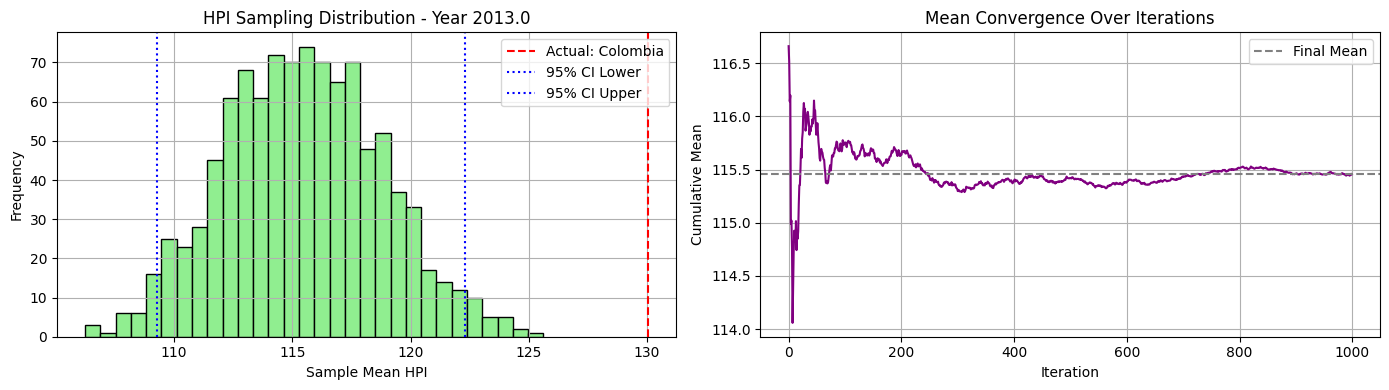

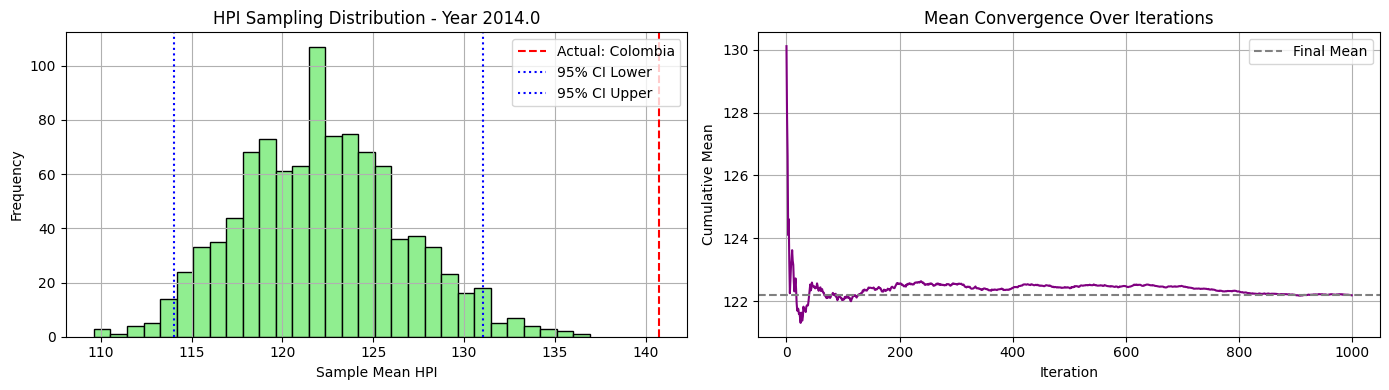

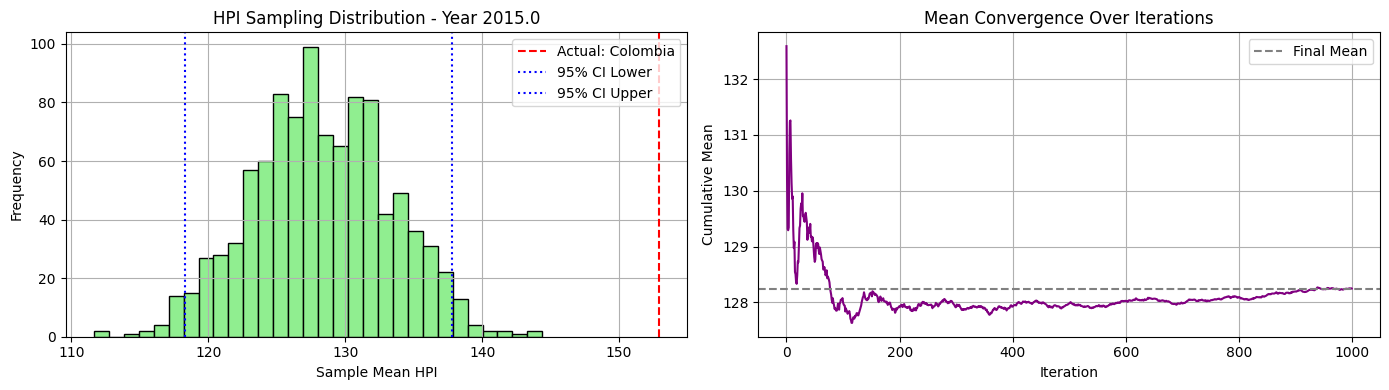

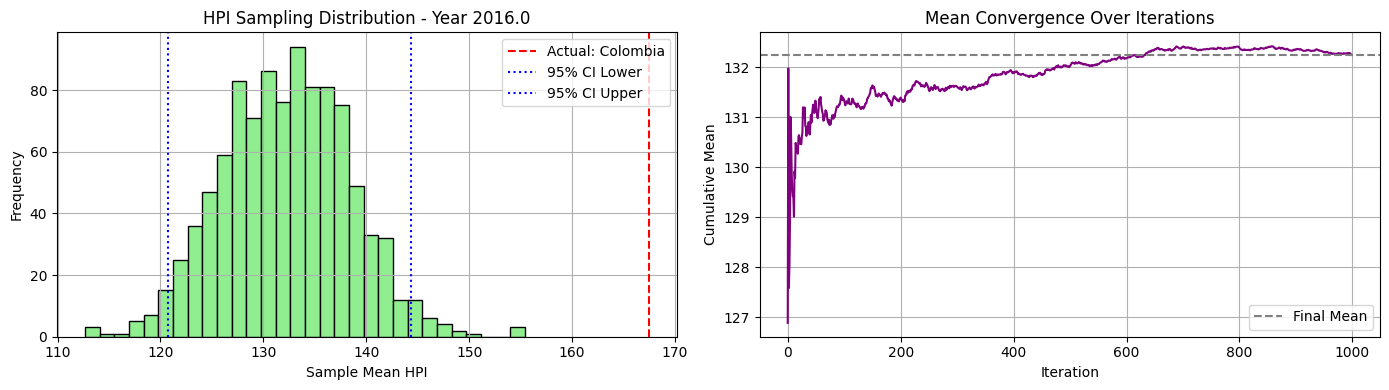

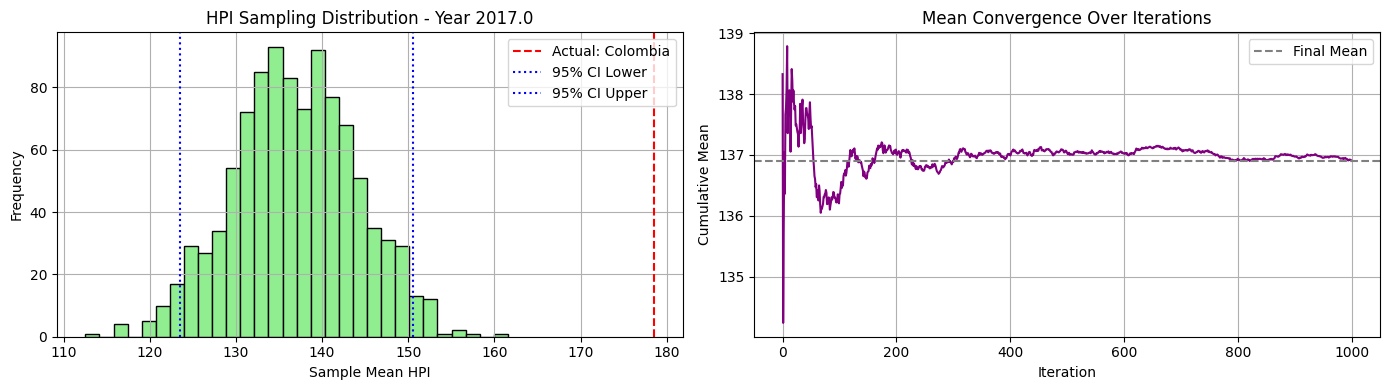

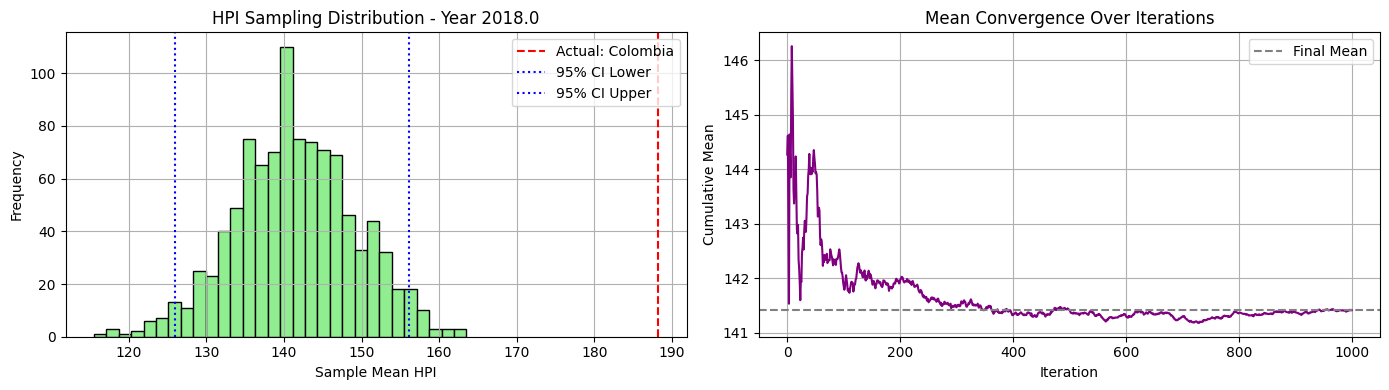

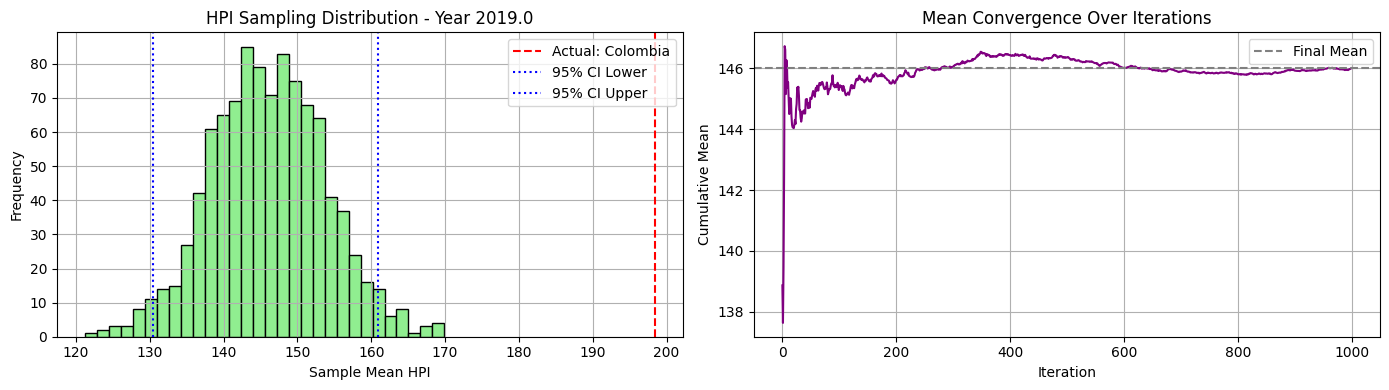

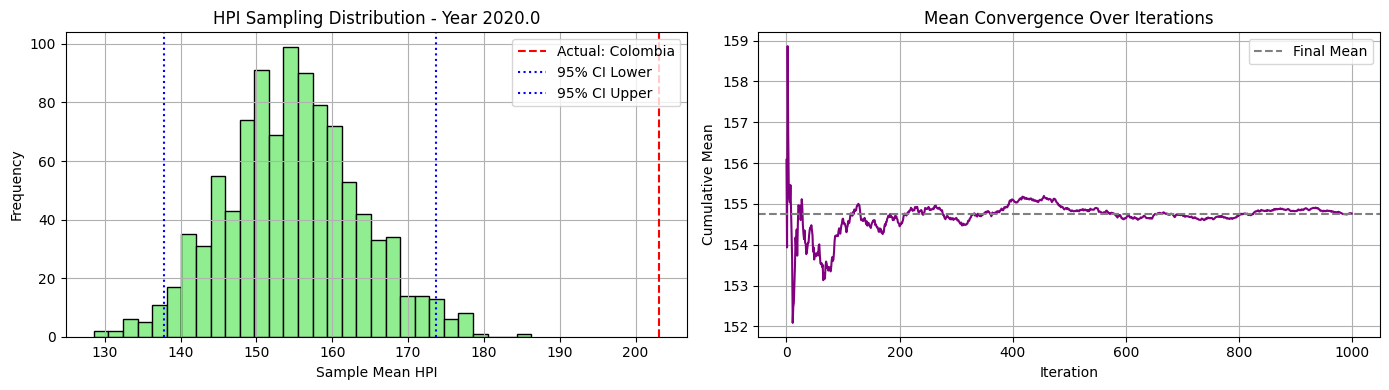

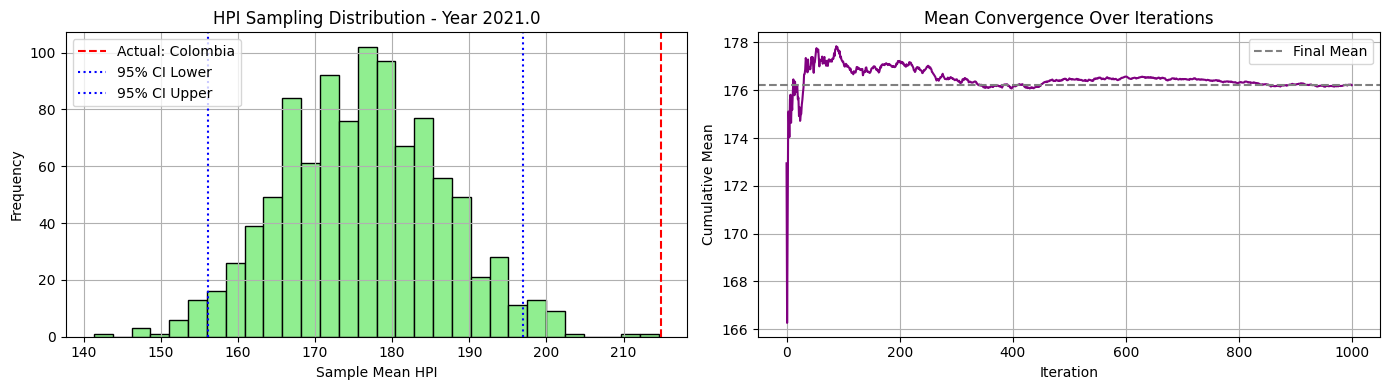

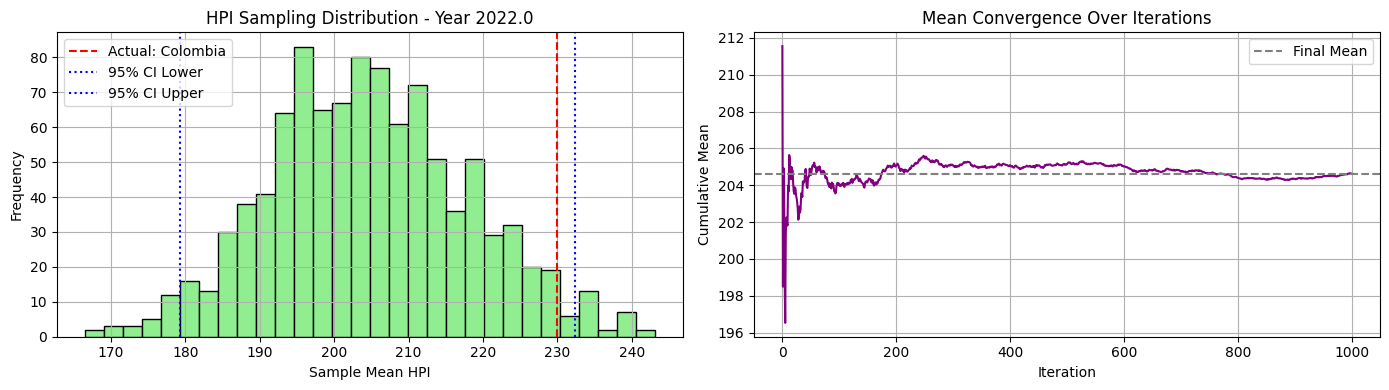

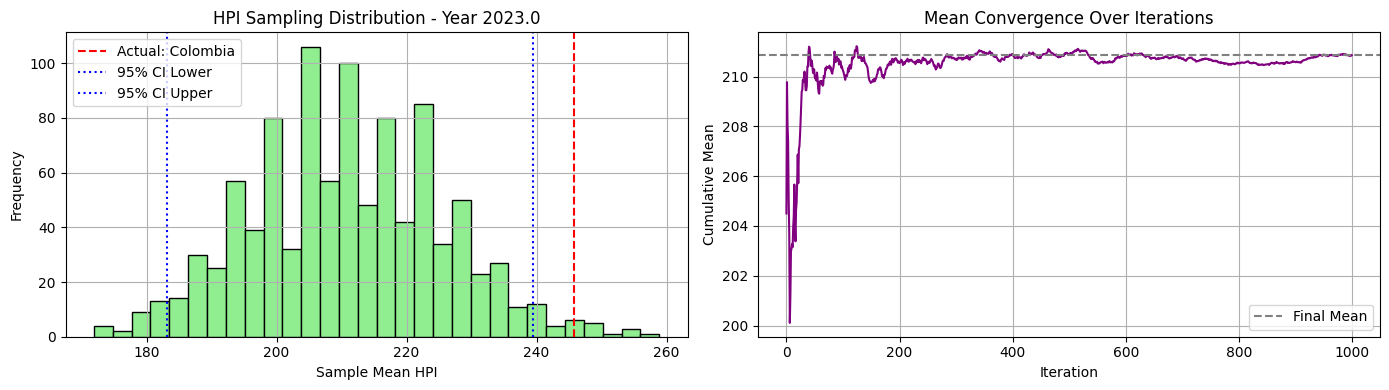

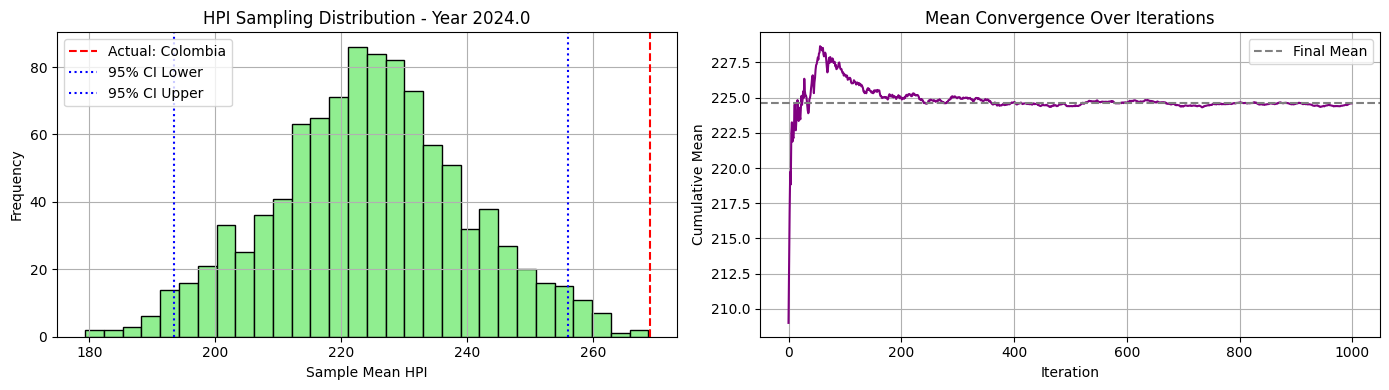

In [29]:
avg_mse_02, avg_mae_02, best_country_02, yearly_bootstrap_means_02, yearly_mean_02 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters, cluster_id=2)

### Compute Metrics

In [30]:
errors = {
    'cluster_0': [avg_mse_00, avg_mae_00],
    'cluster_1': [avg_mse_01, avg_mae_01],
    'cluster_2': [avg_mse_02, avg_mae_02]
}

In [31]:
# Convertir a DataFrame
df_errors = pd.DataFrame.from_dict(errors, orient='index', columns=['Average MSE', 'Average MAE'])

# Formatear valores con 4 decimales
df_errors = df_errors.round(4)

# Imprimir tabla
print("\n📊 Cluster Sampling Error Summary:")
print(df_errors)


📊 Cluster Sampling Error Summary:
           Average MSE  Average MAE
cluster_0    1117.5775      23.8081
cluster_1    1069.6590      23.0133
cluster_2    2886.2969      44.0902


In [32]:
variances = calculate_hpi_variance_by_cluster(df_hpi_winsorized, df_clusters)
for cluster_id, var in variances.items():
    print(f"Cluster {cluster_id}: Avg HPI Variance = {var:.4f}")

Cluster 0: Avg HPI Variance = 1050.9360
Cluster 1: Avg HPI Variance = 1033.3063
Cluster 2: Avg HPI Variance = 2407.8875


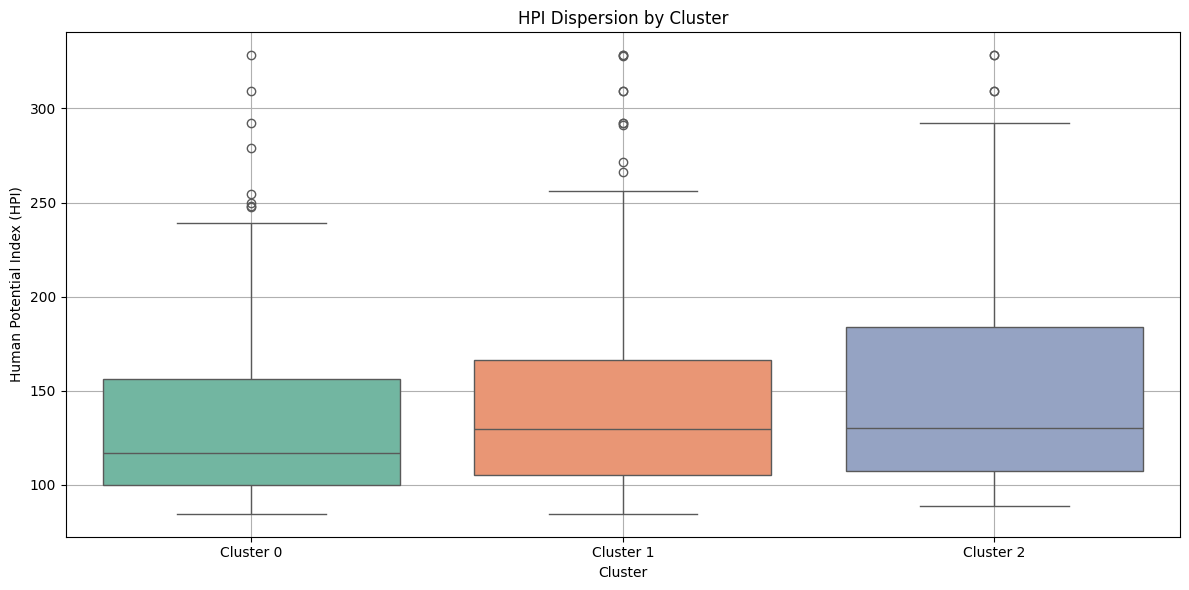

In [35]:
plot_hpi_dispersion_by_cluster(df_hpi_winsorized, df_clusters)

In [36]:
iqr_points= count_points_within_iqr_by_cluster(df_hpi_winsorized, df_clusters)
print(iqr_points)

{np.int32(0): np.int64(143), np.int32(1): np.int64(239), np.int32(2): np.int64(36)}


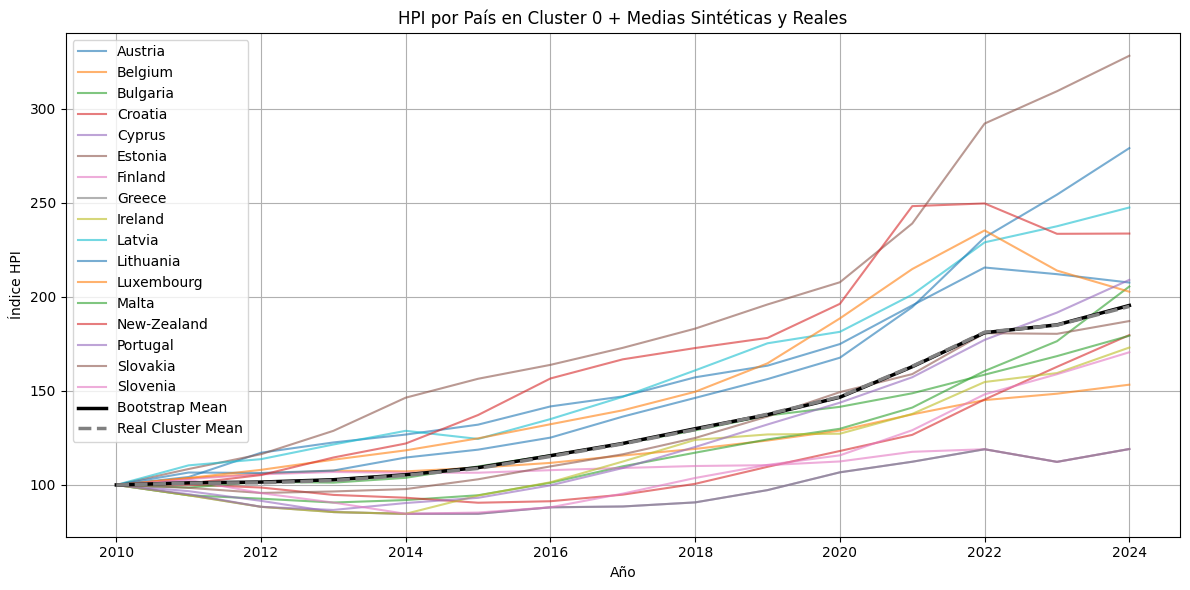

In [37]:
plot_cluster_hpi_with_bootstrap(df_hpi_winsorized, df_clusters, cluster_id=0, yearly_bootstrap_means=yearly_bootstrap_means_00, yearly_mean=yearly_mean_00)

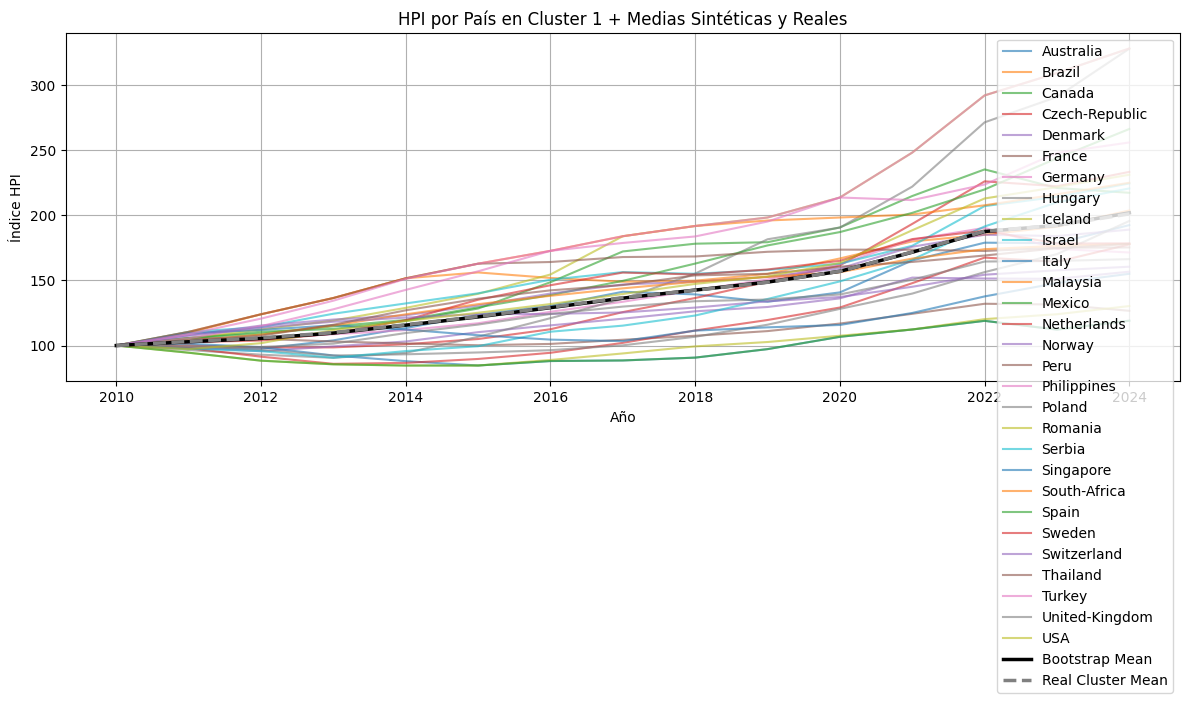

In [38]:
plot_cluster_hpi_with_bootstrap(df_hpi_winsorized, df_clusters, cluster_id=1, yearly_bootstrap_means=yearly_bootstrap_means_01, yearly_mean=yearly_mean_01)

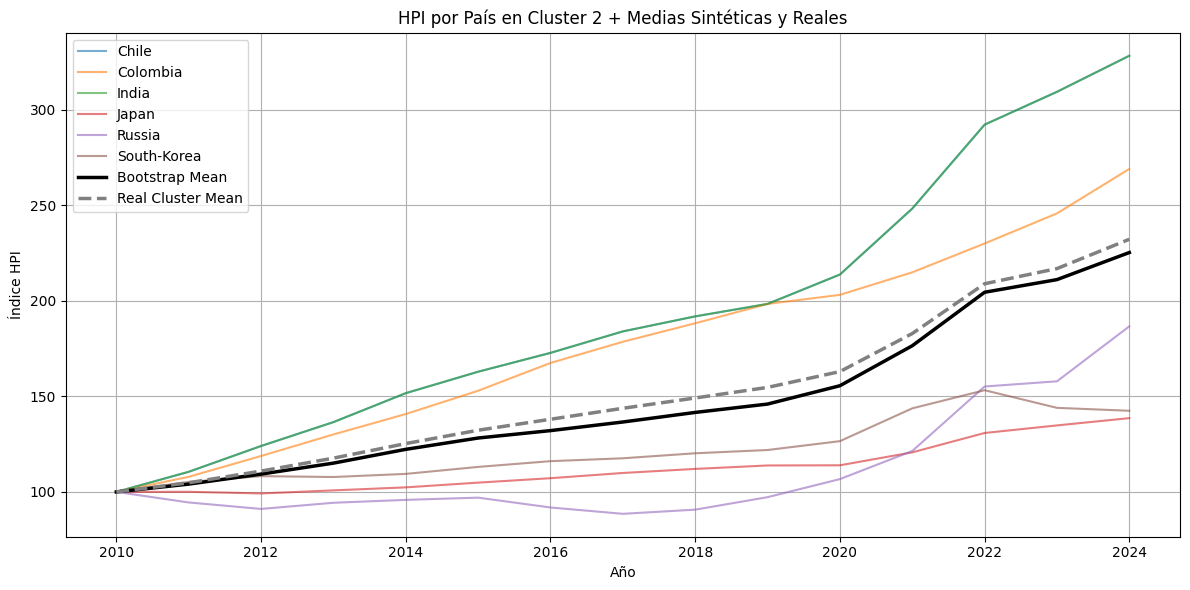

In [39]:
plot_cluster_hpi_with_bootstrap(df_hpi_winsorized, df_clusters, cluster_id=2, yearly_bootstrap_means=yearly_bootstrap_means_02, yearly_mean=yearly_mean_02)

### Log metrics and decisions for experiments

In [40]:
import pandas as pd

In [41]:
from datetime import datetime

In [42]:
log_df = pd.read_parquet('../data/log_performance/clean_sort_log_performance_experiments.parquet')

In [43]:
# Set the option to display all columns
pd.set_option('display.max_columns', None)

In [45]:
log_df

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values,Variance_Cluster_0,Variance_Cluster_1,Variance_Cluster_2,Variance_Cluster_3,IQR_Count_Cluster_0,IQR_Count_Cluster_1,IQR_Count_Cluster_2,IQR_Count_Cluster_3
0,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-20 22:43,None,50,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.563596,"StandardScaler, log transformation",Winsorization x6,True,True,"Winsorization x2, rounding",Winsorization x4,bootstrap,"[32, 43, 52]",3.0,246.836518,11.583352,hypothesis_test_29.ipynb,0.740380,"[0.6591137352377315, 0.08126612096581198]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-16 21:39,None,50,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.393099,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,True,False,"Delete Countries x3, Winsorization x4, rounding",Winsorization x4,bootstrap,"[32, 43, 52]",3.0,246.836518,11.583352,hypothesis_test_23.ipynb,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,kmeans_plusplus_c2_ni10_maxi100_no_3_countries...,2025-09-14 11:38,None,52,KMeans,2,k-means++,10.0,100.0,42.0,True,True,1,0.399803,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,251.809969,11.935068,hypothesis_test_13-percent-exclusion.ipynb,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,kmeans_plusplus_c2_ni20_maxi500_no_3_countries...,2025-09-14 11:39,None,52,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.399803,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,251.809969,11.935068,hypothesis_test_13-percent-exclusion.ipynb,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,kmeans_plusplus_c2_ni20_maxi500_3countries_del...,2025-09-18 17:00,None,50,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.440259,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Delete Countries x3, Winsorization x4, rounding",Winsorization x4,bootstrap,"[32, 43, 52]",3.0,262.010999,12.168987,hypothesis_test_26.ipynb,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,kmeans_plusplus_c2_ni20_maxi500_h2_delteted4_c...,2025-09-17 15:31,None,48,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.441491,"StandardScaler, log transformation, Delete Cou...",Winsorization x6,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Delete Countries x4, Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,266.390743,12.178599,hypothesis_test_24.ipynb,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,kmeans_plusplus_c2_ni20_maxi500_h2_same_seeds_...,2025-09-16 18:52,None,52,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization x6,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,276.897625,12.785992,hypothesis_test_19.ipynb,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,kmeans_plusplus_c2_ni20_maxi500_h2_3_countries...,2025-09-16 18:52,None,52,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.448165,"StandardScaler, log transformation",Winsorization x6,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[23, 32, 46]",3.0,557.401153,18.076755,hypothesis_test_18.ipynb,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,kmeans_plusplus_c2_ni20_maxi500_h2_pca3_3_c

In [46]:
log_df.columns

Index(['experiment_name', 'experiment_date',
       'premacroecon_conversion_transform', 'countries_used_for_clustering',
       'clustering_model', 'n_clusters', 'init_method', 'n_init', 'max_iter',
       'random_state', 'used_elbow_method', 'used_silhouette_score',
       'used_2nd_derivate_for_inflection', 'silhouette_score',
       'transformations_clustering', 'outliers_handling_clustering',
       'used_all_variables_for_clustering', 'used_pca_for_clustering',
       'transformations_sampling', 'outliers_handling_sampling',
       'sampling_method', 'sampling_seed', 'excluded_countries_count',
       'mse_score', 'mae_score', 'source_notebook', 'pca_ratio_sum',
       'pca_ratio_values', 'Variance_Cluster_0', 'Variance_Cluster_1',
       'Variance_Cluster_2', 'Variance_Cluster_3', 'IQR_Count_Cluster_0',
       'IQR_Count_Cluster_1', 'IQR_Count_Cluster_2', 'IQR_Count_Cluster_3'],
      dtype='object')

In [57]:
new_entry = {
    'experiment_name': 'baseline_kmeans_random_3_countries_exclude',
    'experiment_date': '2025-09-13 20:55',
    'premacroecon_conversion_transform': None,
    'countries_used_for_clustering': 52,
    'clustering_model': 'KMeans',
    'n_clusters': 3,
    'init_method': 'random',
    'n_init': 10,
    'max_iter': 100,
    'random_state': 42,
    'used_elbow_method': False,
    'used_silhouette_score': False,
    'used_2nd_derivate_for_inflection': False,
    'silhouette_score': None,
    'transformations_clustering': 'StandardScaler, log transformation',
    'outliers_handling_clustering': None,
    'used_all_variables_for_clustering': True,
    'used_pca_for_clustering': False,
    'transformations_sampling': 'Winsorization, rounding',
    'outliers_handling_sampling': 'Winsorization',
    'sampling_method': 'bootstrap',
    'sampling_seed': None,
    'excluded_countries_count': 52,
    'mse_score': df_errors['Average MSE'].mean(),
    'mae_score': df_errors['Average MAE'].mean(),
    'source_notebook': 'hypothesis_test_07-percent_exclusion',
    'pca_ratio_sum': None,
    'pca_ratio_values': None,
    'Variance_Cluster_0': round(float(variances[0]),2),
    'Variance_Cluster_1': round(float(variances[1]),2),
    'Variance_Cluster_2': round(float(variances[2]),2),
    'Variance_Cluster_3': None,
    'IQR_Count_Cluster_0':int(iqr_points[0]),
    'IQR_Count_Cluster_1':int(iqr_points[1]),
    'IQR_Count_Cluster_2':int(iqr_points[2]),
    'IQR_Count_Cluster_3': None   
}

In [54]:
new_log_df = log_df.copy()

In [55]:
new_log_df = new_log_df.iloc[0:0]

In [59]:
new_log_df = pd.concat([new_log_df, pd.DataFrame([new_entry])], ignore_index=True)

In [60]:
new_log_df

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values,Variance_Cluster_0,Variance_Cluster_1,Variance_Cluster_2,Variance_Cluster_3,IQR_Count_Cluster_0,IQR_Count_Cluster_1,IQR_Count_Cluster_2,IQR_Count_Cluster_3
0,baseline_kmeans_random_3_countries_exclude,2025-09-13 20:55,None,52,KMeans,3,random,10.0,100.0,42.0,False,False,0,None,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,bootstrap,None,52.0,1691.1778,30.303867,hypothesis_test_07-percent_exclusion,None,None,1050.94,1033.31,2407.89,None,143.0,239.0,36.0,None


In [61]:
new_log_df.to_parquet('../data/log_performance/new_log_performance.parquet')